# Step 4b-3 · Automatic digitization: **Qwen3-VL-4B reads, pixels measure**

**Inputs (choose in SETTINGS):**
* `"rebuilt"` — the 12 plots rebuilt in `02_real_plots_multimodel` (6 line / scatter, 4 bar, 2 pie), exact ground truth;
* `"gallery"` — the synthetic gallery in `gallery/` (made by `gallery/make_gallery.py`): **heatmaps, contour / colour maps (2-D surfaces), histograms, box plots, polar plots, stacked and horizontal bars, 3-D bars, 3-D scatter, 3-D surfaces**, several styles each, exact ground truth — plus **10 unsupported plots** (violin, radar, network, Venn, micrograph, ternary, table, multi-panel, dendrogram, schematic) that must be **rejected**;
* any folder of images (CSV + recreated plot, no score).

**Only the VLM describes the plots** — nothing about any figure is typed by hand.

1. **VLM reads text** (Qwen3-VL-4B, local). Question 1: chart type (14 supported types or "other"), axis titles and tick labels. Question 2 depends on the type (series / bar layout / pie slices / histogram series / box categories / heatmap rows, columns and colour bar / polar angle and radius labels / 3-D axes, colour bar, stems).
2. **Pixel check** — tick-label counts, right axis, broken axis (red-box re-ask per piece), y-title re-read.
3. **Digitize** by chart type (one module each, no per-figure settings): `extract.py` line/scatter · `bars.py` vertical bars · `stacked.py` stacked + horizontal bars · `pie.py` · `hist.py` · `boxplot.py` · `heatmap.py` heatmaps + contour maps (colour scale from `colorbar.py`) · `polar.py` · `axes3d.py` 3-D camera (axis lines + ticks → projective camera) + `plot3d.py` 3-D bars / scatter / surfaces.
4. **Rejection gates** (`reject.py`) — every image ends as **ok** (scored), **flagged** (extracted, but part is a guess, e.g. 3-D depth without a cue — not scored) or **rejected** (not extracted: unsupported type, several panels, or a failed self-check such as tick-label fit, labels paired, boxes found, colour-scale distance, camera reprojection). Rejected / flagged images never enter the accuracy mean, and the reason is printed.
5. **Recreate** the plot from the extracted data, and **score** it against the ground truth.

VLM answers are cached per image (`<out_dir>/<figure>/vlm_spec.json`); answers from older prompts are re-asked automatically; when only the pixel checks changed, the cached answers are re-checked (only follow-up questions are asked).

In [1]:
# ============================ SETTINGS (everything configurable is here) ============================
CONFIG = {
    "bench_dir": "../02_real_plots_multimodel",   # rebuilt plots + ground truth + leaderboard come from here
    "images": "gallery",                     # "rebuilt": the 12 rebuilt plots of notebook 02 (scored)
                                             # "gallery": the synthetic gallery of new chart types + unsupported plots (scored)
                                             # or a folder path, e.g. "../data": any plots (CSV + recreated plot, no score)
    "gallery_dir": "gallery",                # images/, truth/, specs/ (specs = what an ideal VLM would read: dry run only)
    "out_dir": "outputs_qwen",               # one folder per VLM run (older Qwen runs: outputs_v2, outputs_v3; OpenAI: outputs_openai)

    "spec_source": "qwen",                   # "qwen": local Qwen3-VL (free) | "openai": OpenAI API (paid)
                                             # "files": spec files instead of a VLM (dry run): manual_specs/, or gallery/specs/ for the gallery
    # --- Qwen (local, runs on the Mac - no cost)
    "qwen_model": "Qwen/Qwen3-VL-4B-Instruct",
    "max_new_tokens": 1024,
    # --- OpenAI (paid) - switched off; to use it set spec_source = "openai" and uncomment these
    # "openai_model": "gpt-6-astra",         # most capable OpenAI model with image input; cheaper: "gpt-6.1-sol"
    # "openai_detail": "high",               # "high" | "original" | "auto"
    # "openai_reasoning": "medium",          # "low" | "medium" | "high"
    "upscale_below": 1000,                   # images smaller than this are enlarged for the VLM only (small labels read better)
    "use_cache": True,                       # reuse saved VLM answers. False: ask again
    "pixel_check": True,                     # cross-check the VLM answer with the pixels and re-ask where they disagree

    "hit_threshold": 5.0,                    # % of the y-axis span
}
# To FIX a VLM mistake for one image: edit "spec" in <out_dir>/<figure>/vlm_spec.json and re-run (use_cache=True).

In [2]:
import json, time, sys, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)

sys.path.insert(0, ".")
import autodig
from autodig import QwenSpecReader, OpenAISpecReader, FileSpecReader, pipeline, recreate, read_spec, side_by_side, evaluate as E, report as RP
from autodig.run import _jsonable

BENCH, OUT = Path(CONFIG["bench_dir"]), Path(CONFIG["out_dir"])
OUT.mkdir(exist_ok=True)
MODE = CONFIG["images"] if CONFIG["images"] in ("rebuilt", "gallery") else "folder"
SCORED = MODE == "rebuilt"
GAL = Path(CONFIG["gallery_dir"])
if not (GAL / "images").exists() and Path("gallery.zip").exists():      # first run: unpack the gallery
    import zipfile
    zipfile.ZipFile("gallery.zip").extractall(".")
    print("unpacked gallery.zip ->", GAL)
if MODE == "gallery":
    from autodig import gallery_eval as GE
    IMAGES = {p.stem: p for p in sorted((GAL / "images").glob("*.png"))}
    GT = {n: json.loads((GAL / "truth" / f"{n}.json").read_text()) for n in IMAGES}
elif SCORED:
    FIGURES, score_figure = RP.load_chartbench(BENCH)
    import chartbench.config as cbcfg
    cbcfg.CONFIG["scoring"]["hit_threshold"] = CONFIG["hit_threshold"]
    IMAGES = {fid: BENCH / "outputs" / "rebuilt_plots" / f"{fid}_rebuilt.png" for fid in FIGURES}
    GT = {fid: json.loads((BENCH / "outputs" / "ground_truth" / f"{fid}.json").read_text()) for fid in FIGURES}
if MODE == "folder":
    folder = Path(CONFIG["images"])
    IMAGES = {p.stem[:40]: p for p in sorted(folder.iterdir()) if p.suffix.lower() in (".png", ".jpg", ".jpeg")}
for n, p in IMAGES.items():
    print(f"{n:20s} <- {p}")

bar3d_1              <- gallery/images/bar3d_1.png
bar3d_2              <- gallery/images/bar3d_2.png
bar3d_3              <- gallery/images/bar3d_3.png
box_1                <- gallery/images/box_1.png
box_2                <- gallery/images/box_2.png
box_3                <- gallery/images/box_3.png
box_4                <- gallery/images/box_4.png
box_5                <- gallery/images/box_5.png
field_1              <- gallery/images/field_1.png
field_2              <- gallery/images/field_2.png
field_3              <- gallery/images/field_3.png
field_4              <- gallery/images/field_4.png
hbar_1               <- gallery/images/hbar_1.png
heatmap_1            <- gallery/images/heatmap_1.png
heatmap_2            <- gallery/images/heatmap_2.png
heatmap_3            <- gallery/images/heatmap_3.png
heatmap_4            <- gallery/images/heatmap_4.png
hist_1               <- gallery/images/hist_1.png
hist_2               <- gallery/images/hist_2.png
hist_3               <- gallery/imag

## 0 · The VLM reader
Loaded lazily: if every answer is cached, the model is never loaded. The questions it is asked:

In [3]:
if CONFIG["spec_source"] == "qwen":
    reader = QwenSpecReader(CONFIG["qwen_model"], max_new_tokens=CONFIG["max_new_tokens"], upscale_below=CONFIG["upscale_below"])
# elif CONFIG["spec_source"] == "openai":    # OpenAI API (paid) - switched off
#     import os, getpass
#     try:
#         import openai
#     except ImportError:
#         %pip install -q openai
#     if not os.environ.get("OPENAI_API_KEY"):
#         os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key (kept in memory only): ")
#     reader = OpenAISpecReader(CONFIG["openai_model"], detail=CONFIG["openai_detail"],
#                               reasoning_effort=CONFIG["openai_reasoning"], upscale_below=CONFIG["upscale_below"])
else:
    reader = FileSpecReader(str(GAL / "specs") if MODE == "gallery" else "manual_specs")   # spec files - NOT VLM output
print("spec source:", type(reader).__name__, getattr(reader, "model_id", ""))
print("\n--- question 1: axes ---\n" + autodig.AXES_PROMPT)
print("\n--- question 2: series ---\n" + autodig.SERIES_PROMPT)
print("\n--- question 2 for a BAR chart ---\n" + autodig.BAR_PROMPT)
print("\n--- question 2 for a PIE chart ---\n" + autodig.PIE_PROMPT)
for nm in ("STACK_PROMPT", "HIST_PROMPT", "BOX_PROMPT", "HEATMAP_PROMPT", "POLAR_PROMPT", "THREED_PROMPT"):
    print(f"\n--- question 2: {nm} ---\n" + getattr(autodig, nm))
print("\n--- follow-up when pixels disagree ---\n" + autodig.TICKS_PROMPT)
print("\n--- follow-up per piece of a broken axis (red box drawn on the image) ---\n" + autodig.BOX_TICKS_PROMPT)

spec source: QwenSpecReader Qwen/Qwen3-VL-4B-Instruct

--- question 1: axes ---
You are reading a scientific chart. Report its axes as JSON, copying text exactly as printed.
Return ONLY this JSON object:
{
 "chart_type": one of "scatter", "line", "scatter_line", "bar", "stacked_bar", "histogram", "box", "heatmap", "contour", "polar", "pie", "bar3d", "scatter3d", "surface3d", "other",
 "x_axis": {"title": "<x-axis title>", "tick_labels": ["<every numeric tick label under the x-axis, left to right>"], "scale": "linear" or "log"},
 "y_axis": {"title": "<left y-axis title>", "tick_labels": ["<every numeric tick label on the LEFT y-axis, bottom to top>"], "scale": "linear" or "log", "broken": true or false},
 "y_axis_right": null or {"title": "...", "tick_labels": ["<every numeric tick label on the RIGHT side, bottom to top>"], "scale": "linear" or "log"}
}
Rules:
- Copy every tick label exactly as printed (e.g. "0.0003", "1.0", "10"). Count them: do not skip any, do not add values that are

## 1 · VLM reads each image (text only), pixels check the answer
The full answers, re-asks and pixel checks are saved in `<out_dir>/<figure>/vlm_spec.json`.

In [4]:
spec_info, specs = {}, {}
for name, img in IMAGES.items():
    sp = read_spec(img, reader, OUT / name / "vlm_spec.json", CONFIG["use_cache"], CONFIG["pixel_check"])
    spec_info[name], specs[name] = sp, sp["spec"]
    S_ = sp["spec"]
    what = ([f"{q['name']} ({q['printed_value']}%)" for q in S_.get("slices", [])] if S_.get("chart_type") == "pie"
            else [s["name"] for s in S_["series"]])
    cl = S_.get("categories") or S_.get("rows") or []
    cats = f"  categories: {[c['name'] if isinstance(c, dict) else c for c in cl]}" if cl else ""
    print(f"{name:15s} {'cached' if sp['from_cache'] else 'read now'}  type: {S_.get('chart_type')}  "
          f"{'slices' if S_.get('chart_type') == 'pie' else 'series'}: {what}{cats}")
    for c in sp.get("checks", []):
        print(f"{'':12s}pixel check: {c}")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


bar3d_1         read now  type: bar3d  series: []
            pixel check: no axes found in the image (no axis line found)
bar3d_2         read now  type: bar3d  series: ['pH 4', 'pH 6', 'pH 8', 'pH 10', 'pH 12']
            pixel check: no axes found in the image (no axis line found)
bar3d_3         read now  type: bar3d  series: []
            pixel check: no axes found in the image (no axis line found)
box_1           read now  type: box  series: ['P removal (%)']  categories: ['Control', 'BC300', 'BC500', 'BC700', 'Fe-BC']
            pixel check: y_axis: VLM listed 9 tick labels, pixels found 8; labels still line up (fit 0.3 px) - kept
box_2           read now  type: box  series: ['P removal (%) #1', 'P removal (%) #2', 'P removal (%) #3', 'P removal (%) #4', 'P removal (%) #5']  categories: ['Control', 'BC300', 'BC500', 'BC700', 'Fe-BC']
            pixel check: y_axis: VLM listed 9 tick labels, pixels found 8; labels still line up (fit 0.3 px) - kept
box_3           read now  ty

## 2 · Digitize → `extracted.csv`, and recreate the plot from it
Markers: one row per marker. Curves without markers: the traced curve is kept only where it bends (within ½ pixel), so a curve has tens of points, not one per pixel column. Bars: one row per bar (x = category index, `category` = its name, `yerr` = error bar). Pies: one row per slice (x = slice index clockwise from 12 o'clock).

bar3d_1              OK        type: bar3d  rows: 16
                      4 grid cells without a visible bar top (hidden behind taller bars, or zero)


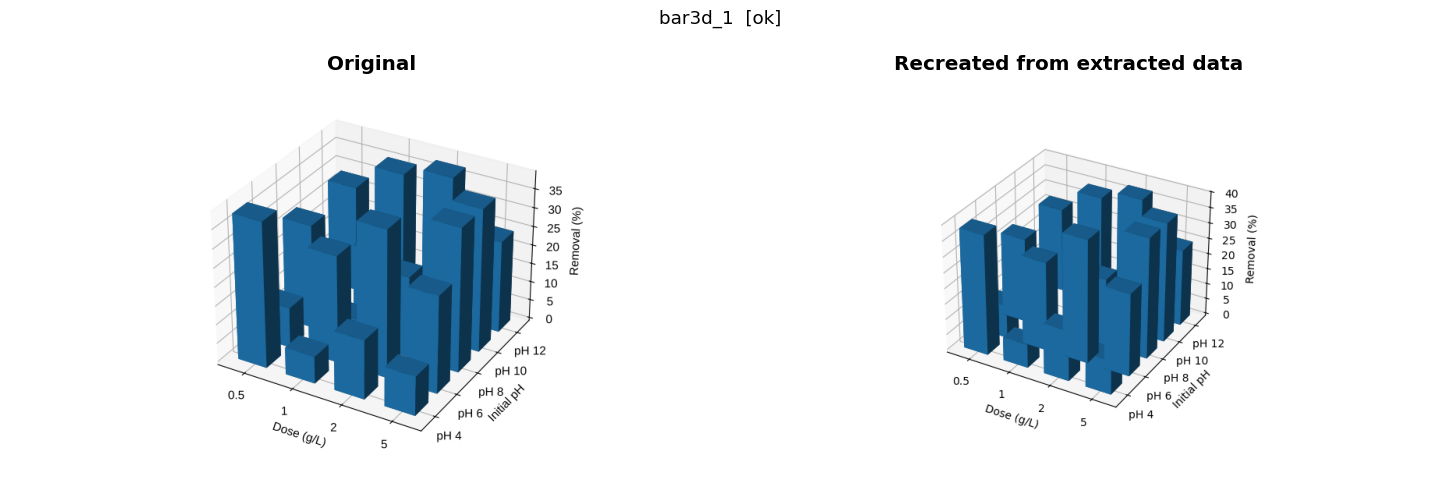

bar3d_2              OK        type: bar3d  rows: 15
                      5 grid cells without a visible bar top (hidden behind taller bars, or zero)


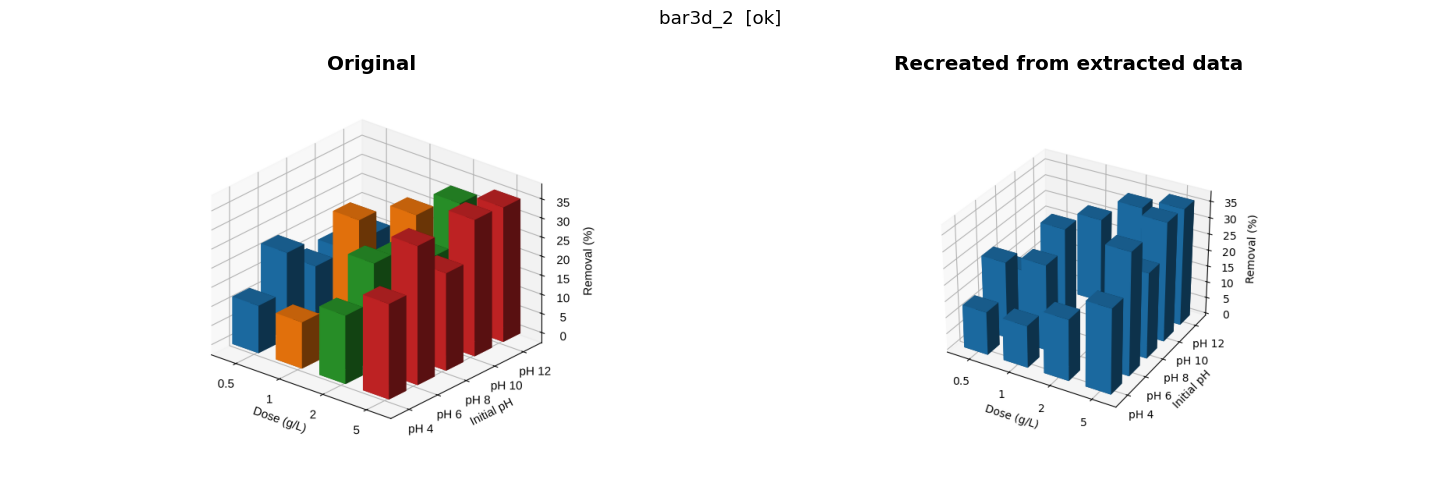

bar3d_3              OK        type: bar3d  rows: 11
                      9 grid cells without a visible bar top (hidden behind taller bars, or zero)


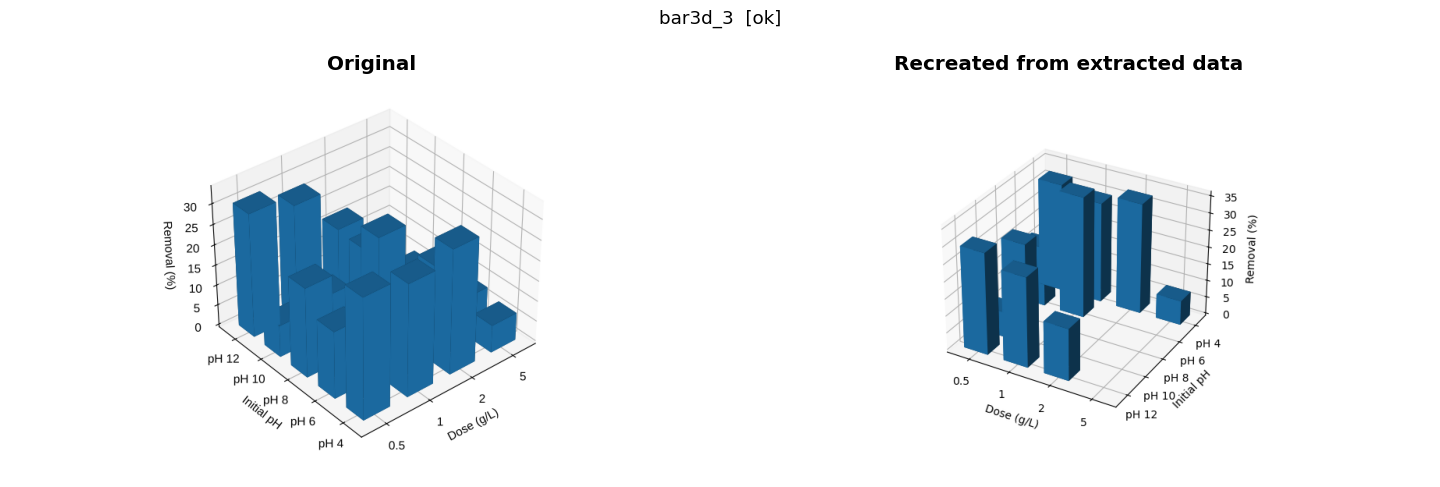

box_1                OK        type: box  rows: 5


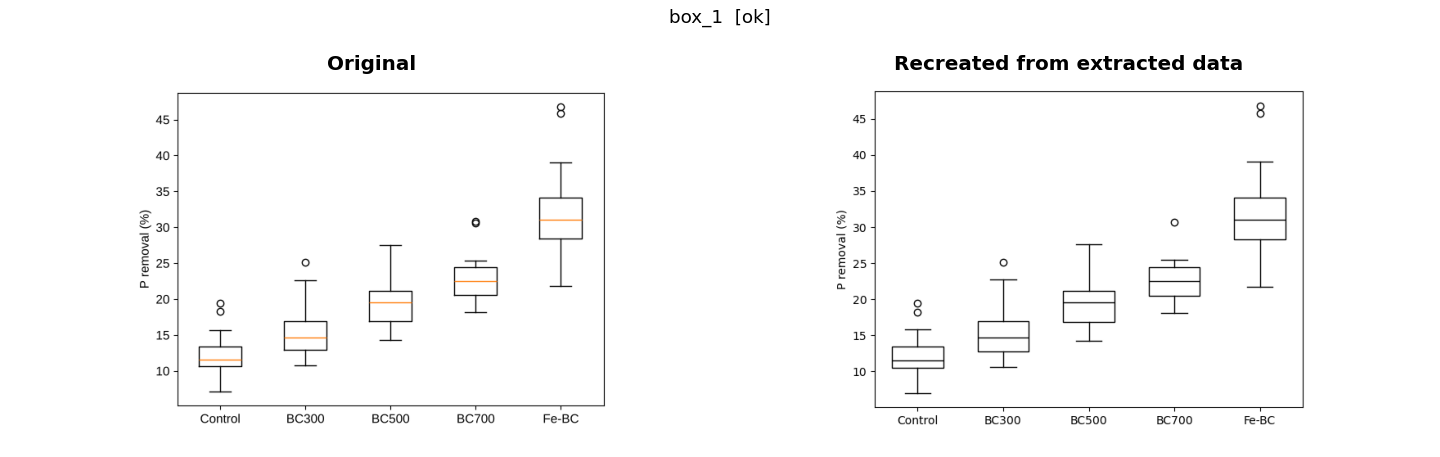

box_2                REJECTED  type: box  rows: 5
                      self-check failed: boxes found / expected = 5/25 (needs equal)
                      VLM: 5 categories x 5 series = 25 boxes, pixels found 5


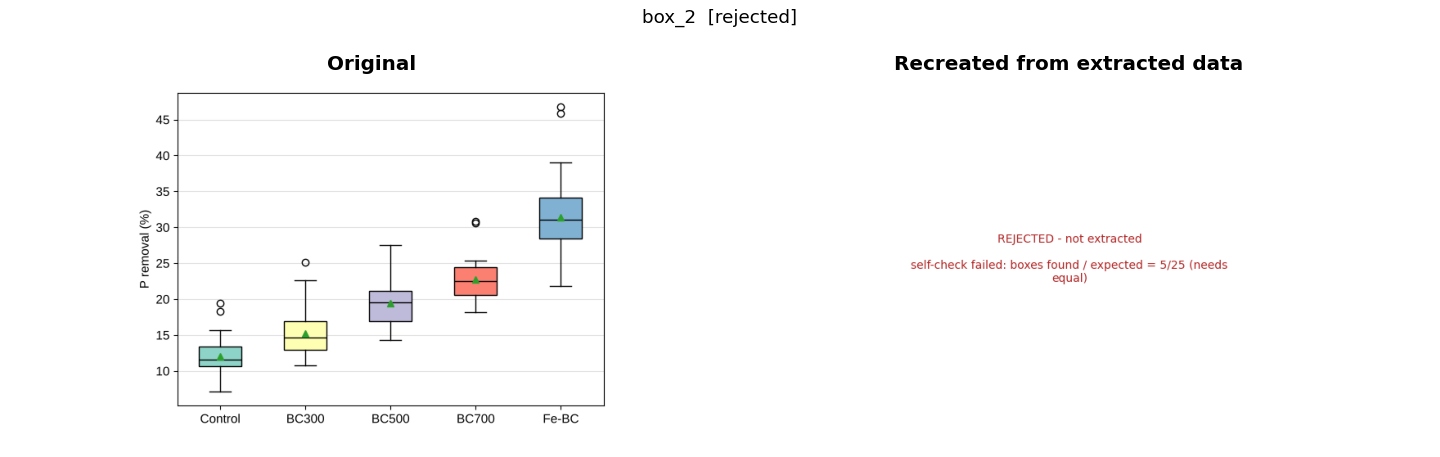

box_3                REJECTED  type: box  rows: 0
                      box plot: the value axis has no numeric calibration


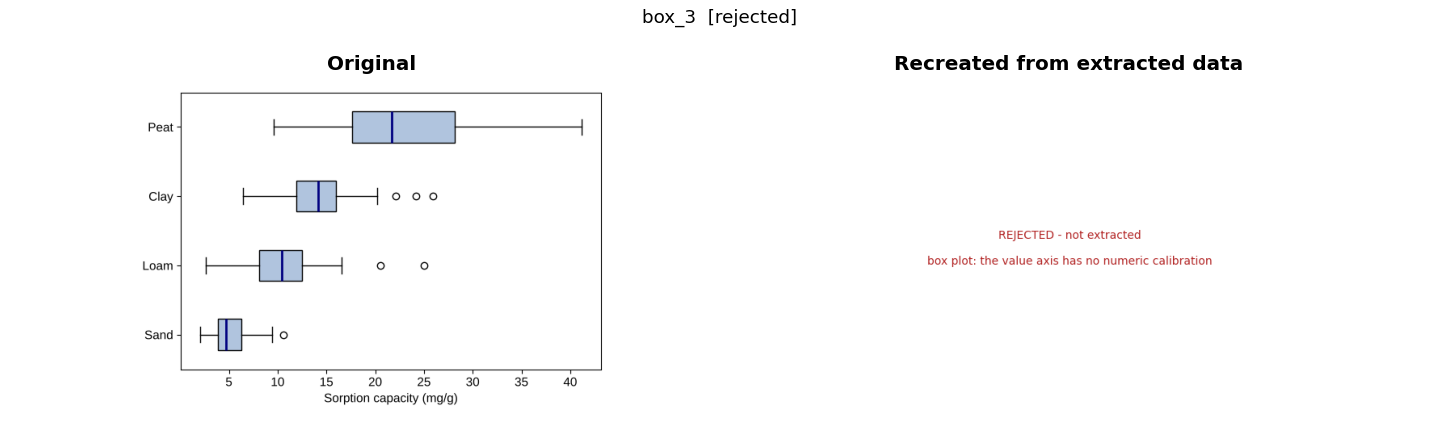

box_4                OK        type: box  rows: 6


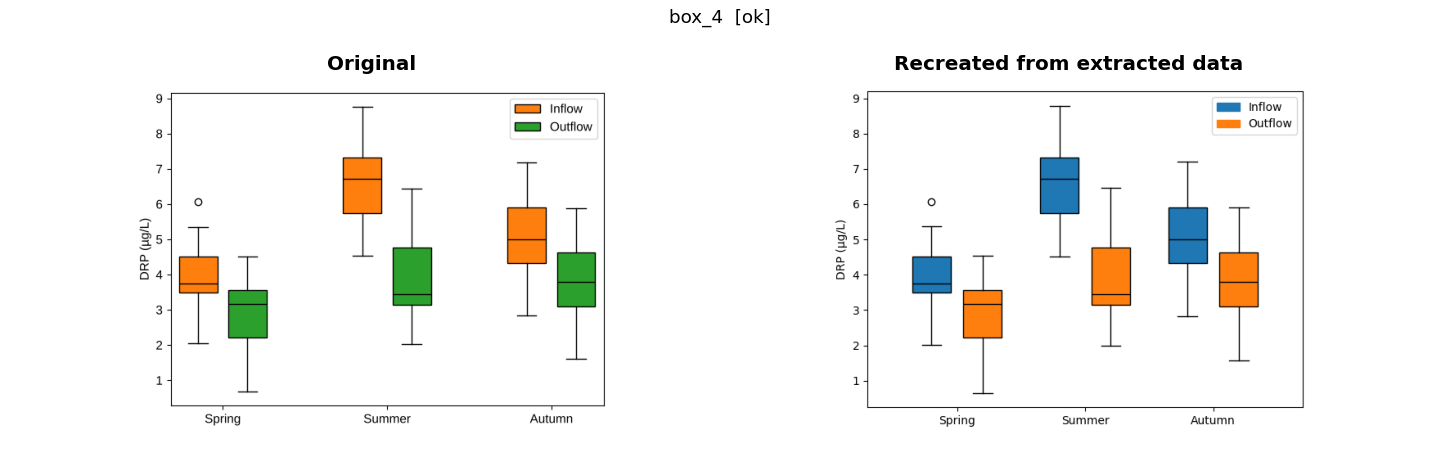

box_5                OK        type: box  rows: 4


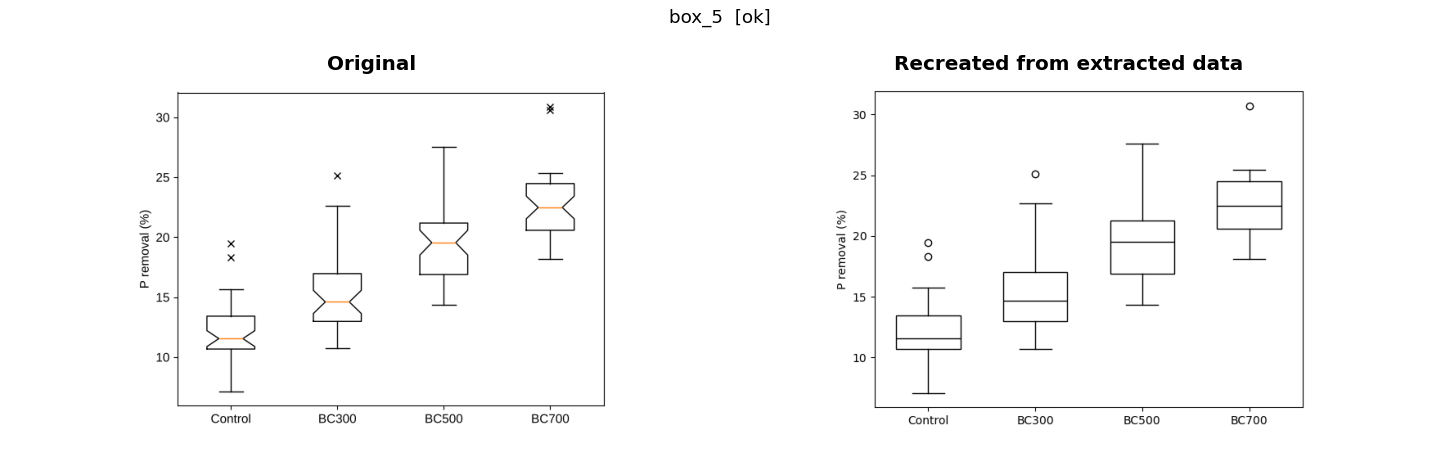

field_1              OK        type: contour  rows: 3600


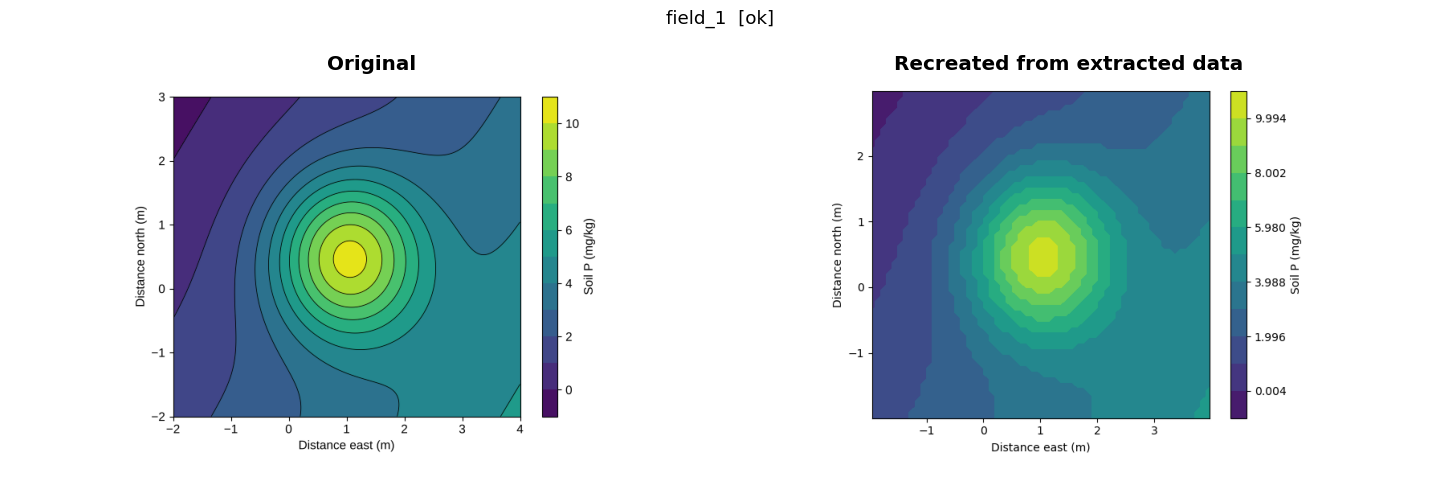

field_2              OK        type: heatmap  rows: 1


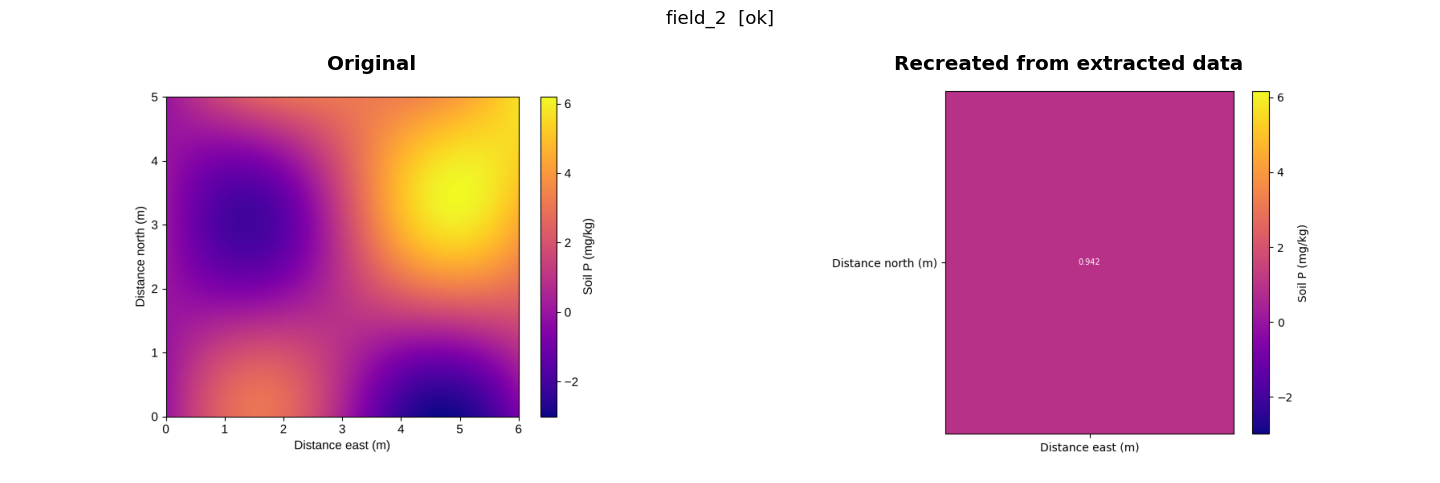

field_3              OK        type: contour  rows: 3600


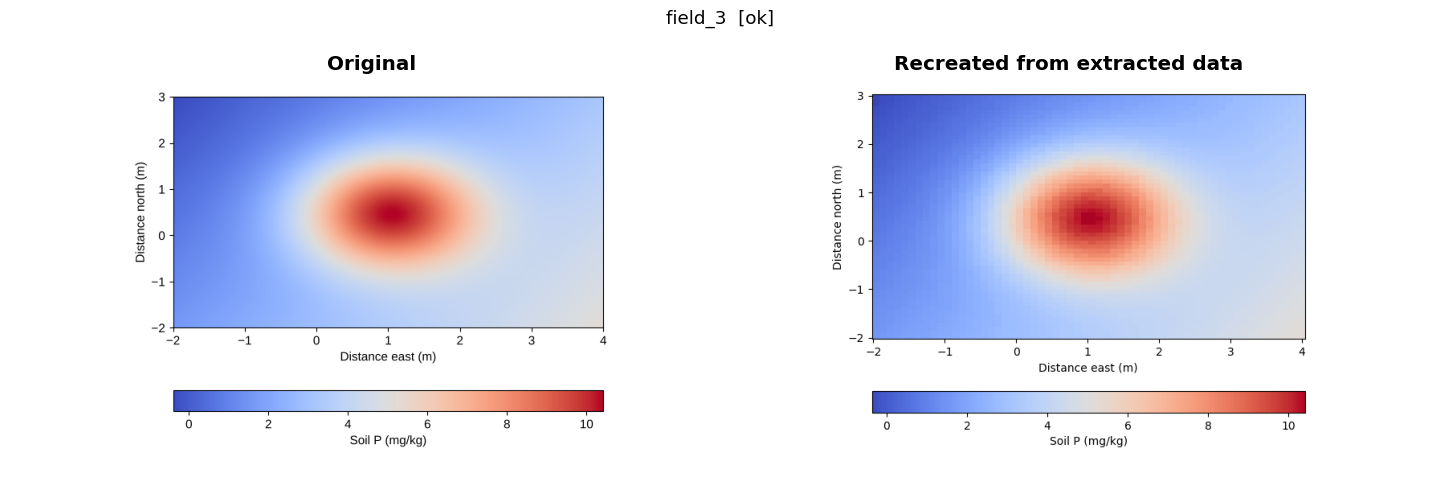

field_4              OK        type: contour  rows: 3600


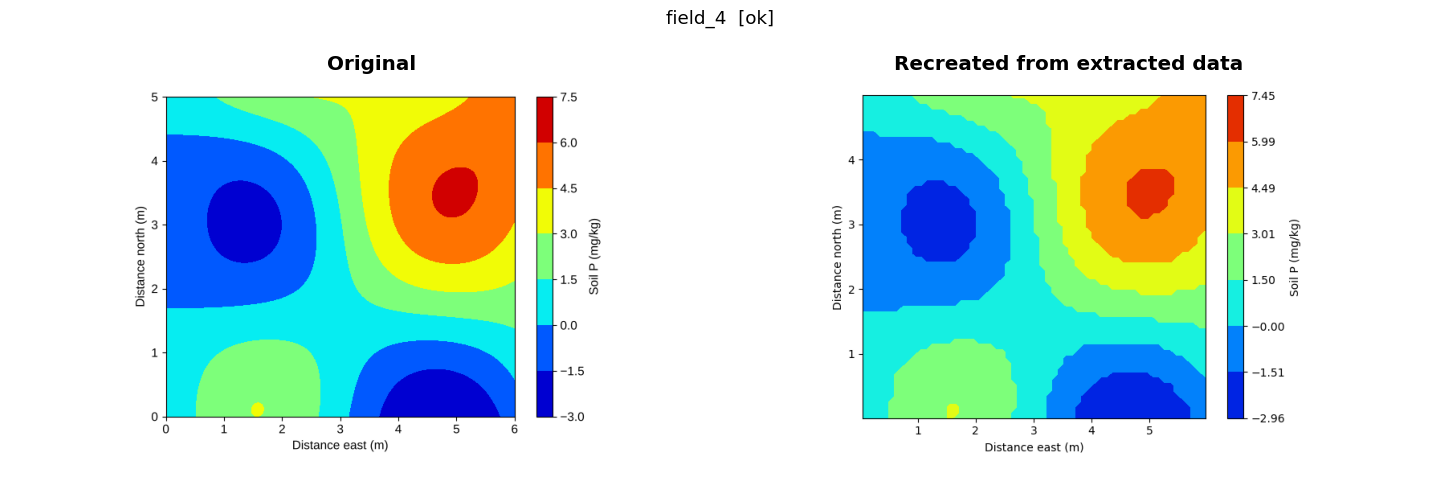

hbar_1               OK        type: bar  rows: 2
                      VLM listed 4 categories, the pixels show 1 groups of bars - pixels used


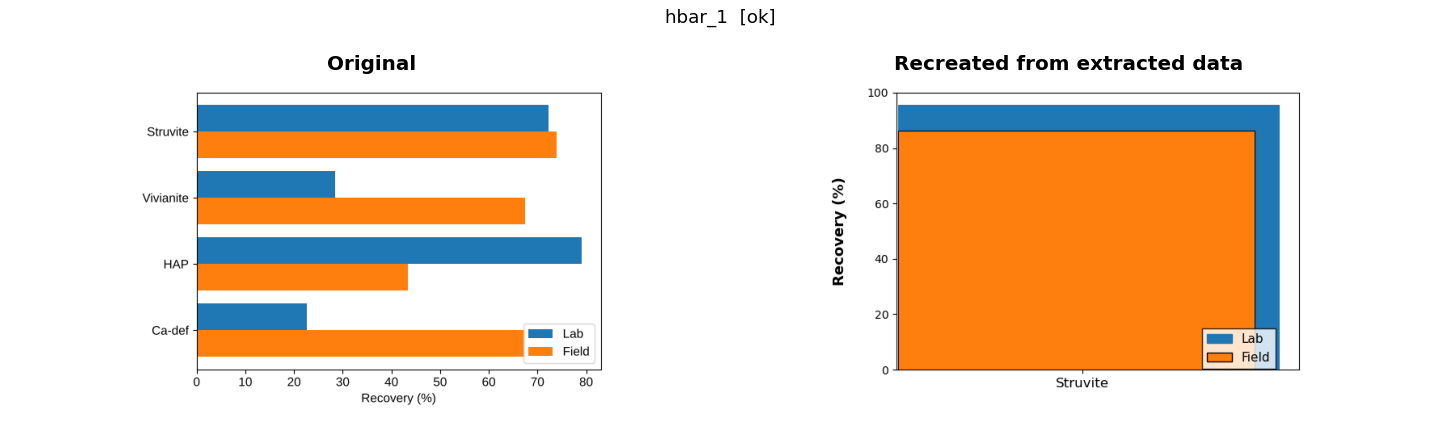

heatmap_1            OK        type: heatmap  rows: 48


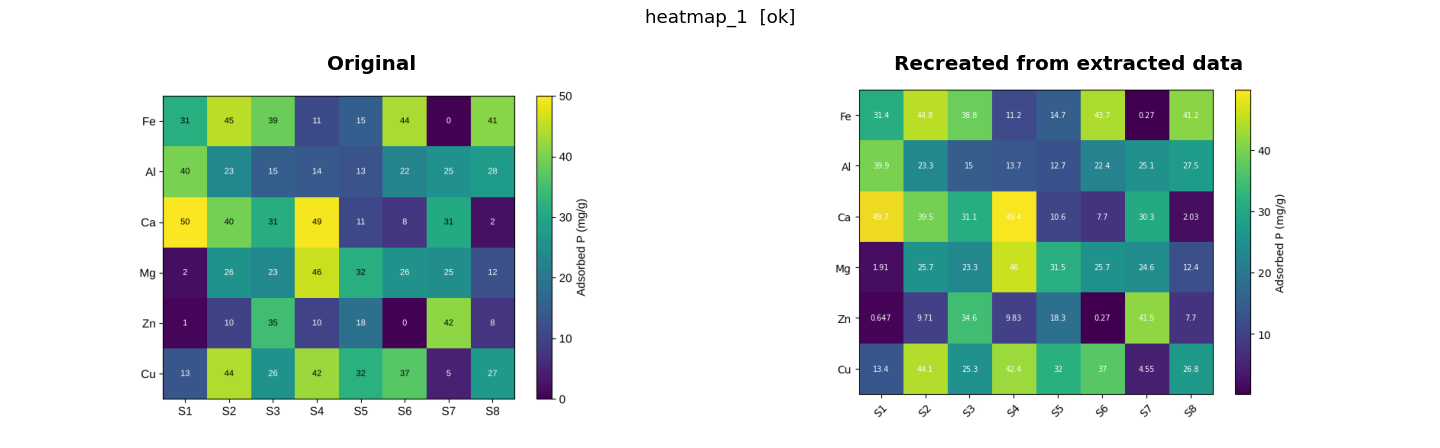

heatmap_2            OK        type: heatmap  rows: 81


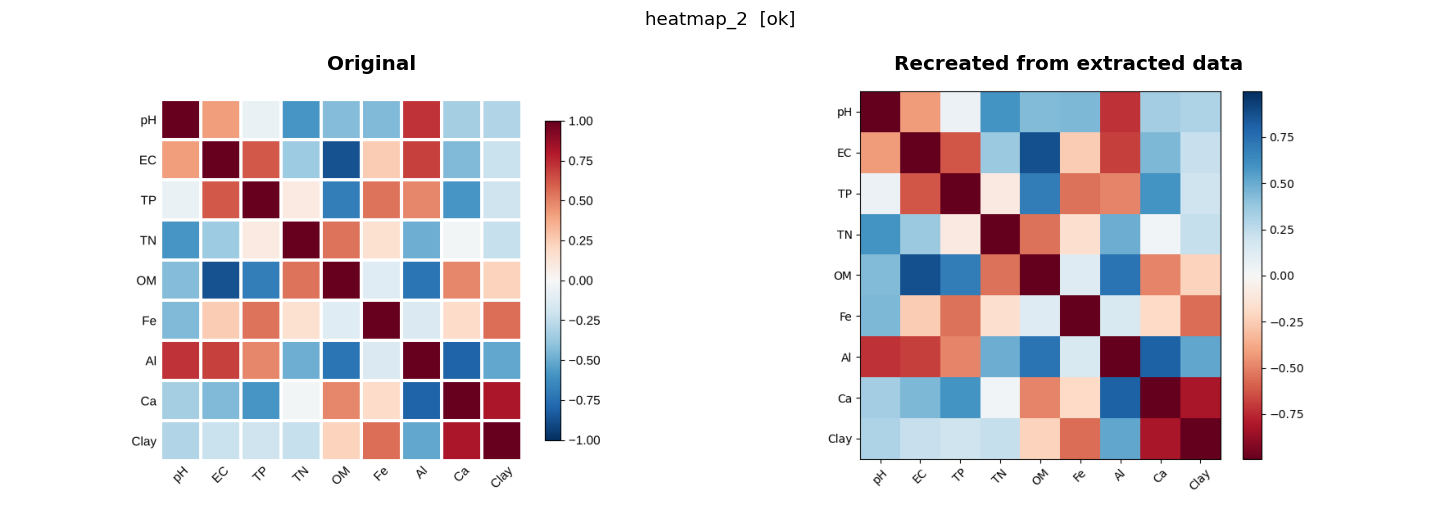

heatmap_3            OK        type: heatmap  rows: 60


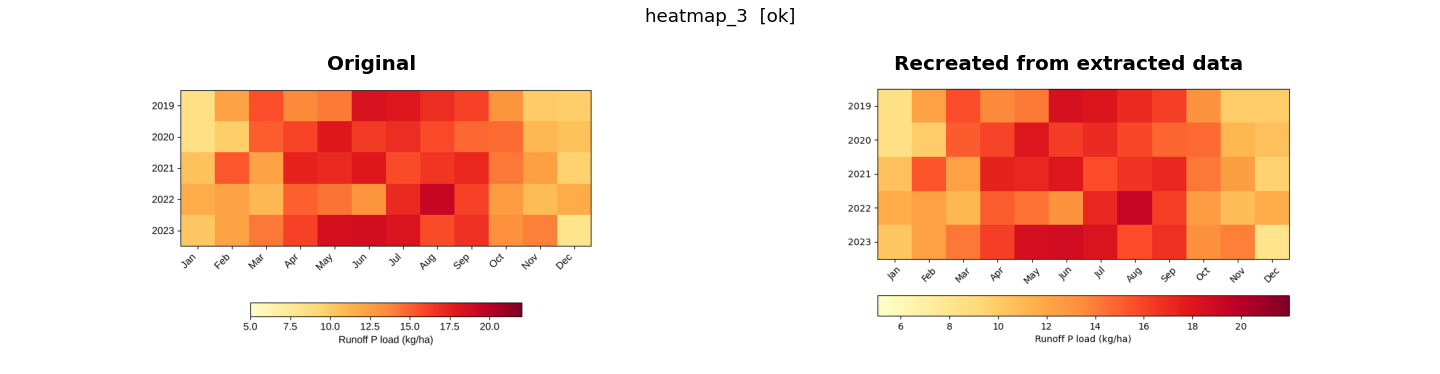

heatmap_4            OK        type: heatmap  rows: 20


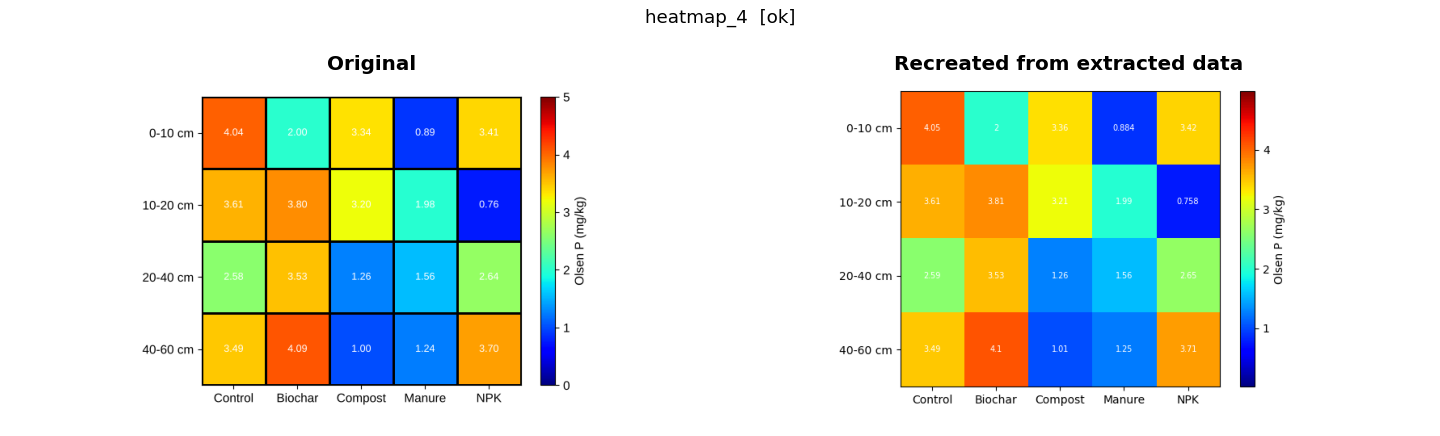

hist_1               OK        type: histogram  rows: 17


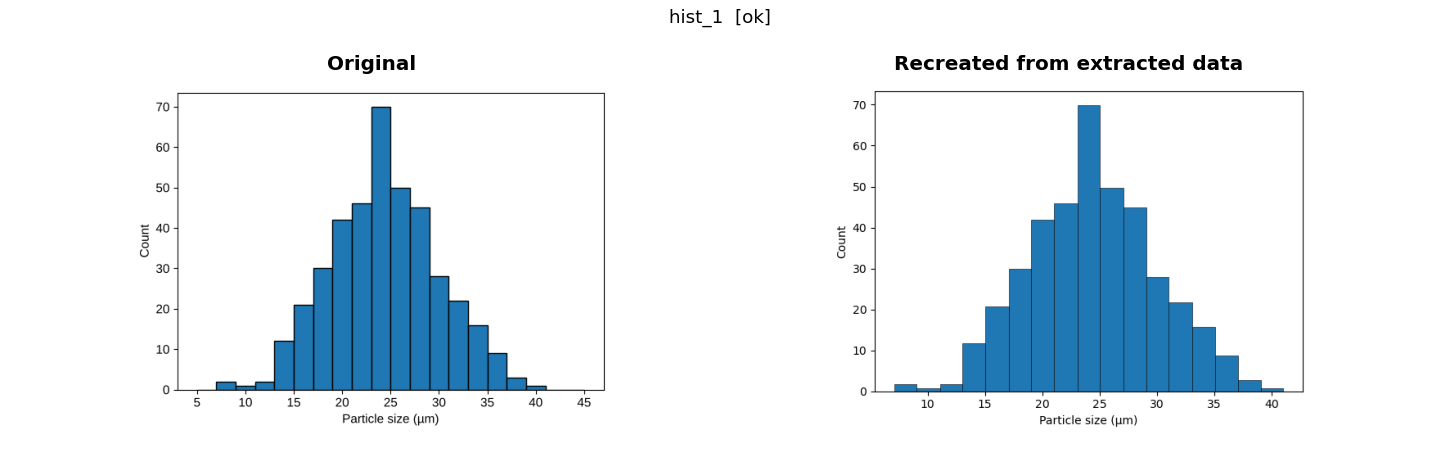

hist_2               OK        type: histogram  rows: 43


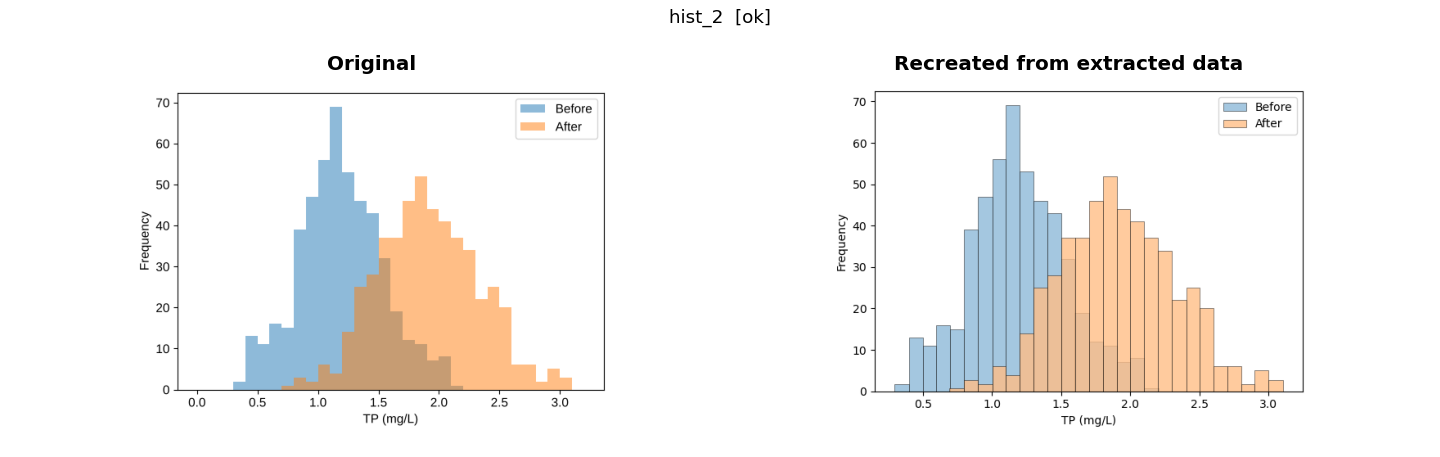

hist_3               OK        type: histogram  rows: 16


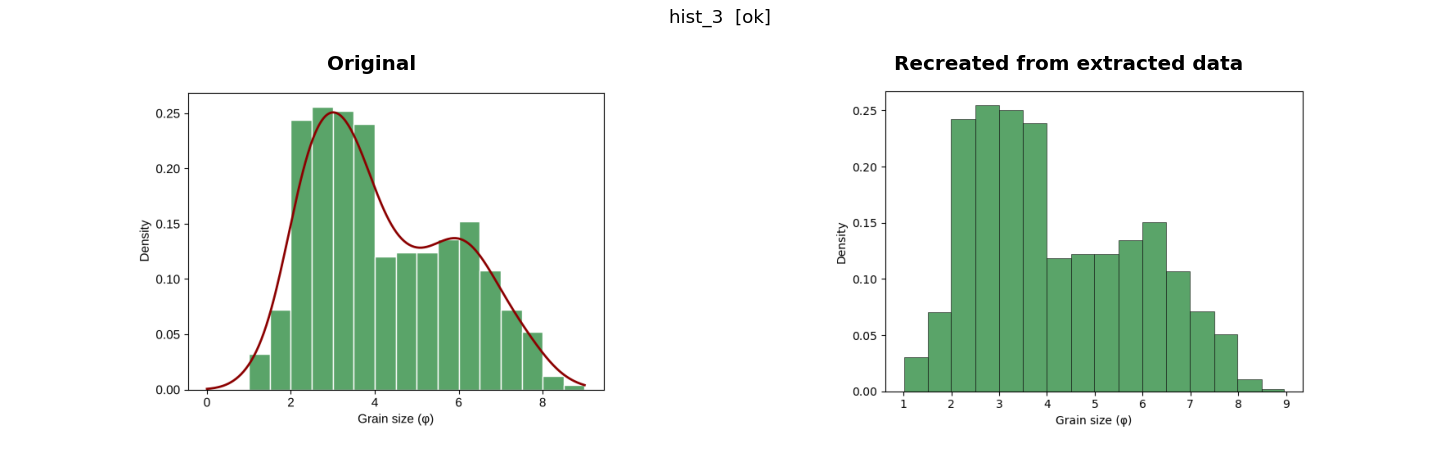

hist_4               OK        type: None  rows: 116


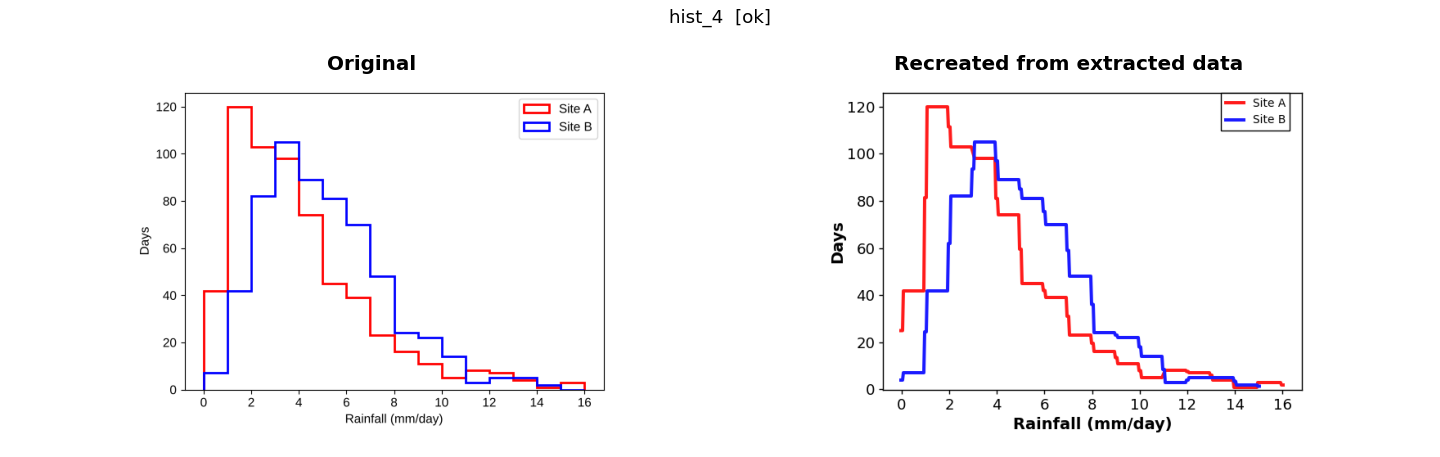

polar_1              OK        type: polar  rows: 704


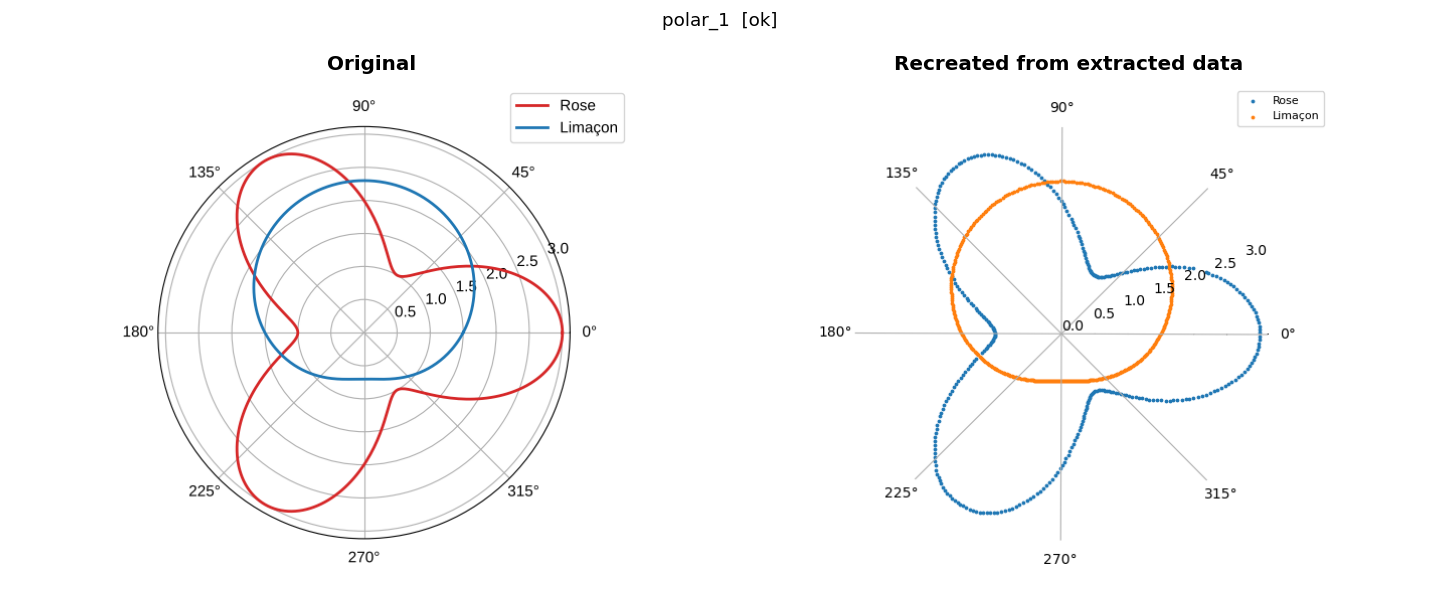

polar_2              REJECTED  type: polar  rows: 0
                      polar: angle calibration failed (the angle labels' order fits neither turning direction)


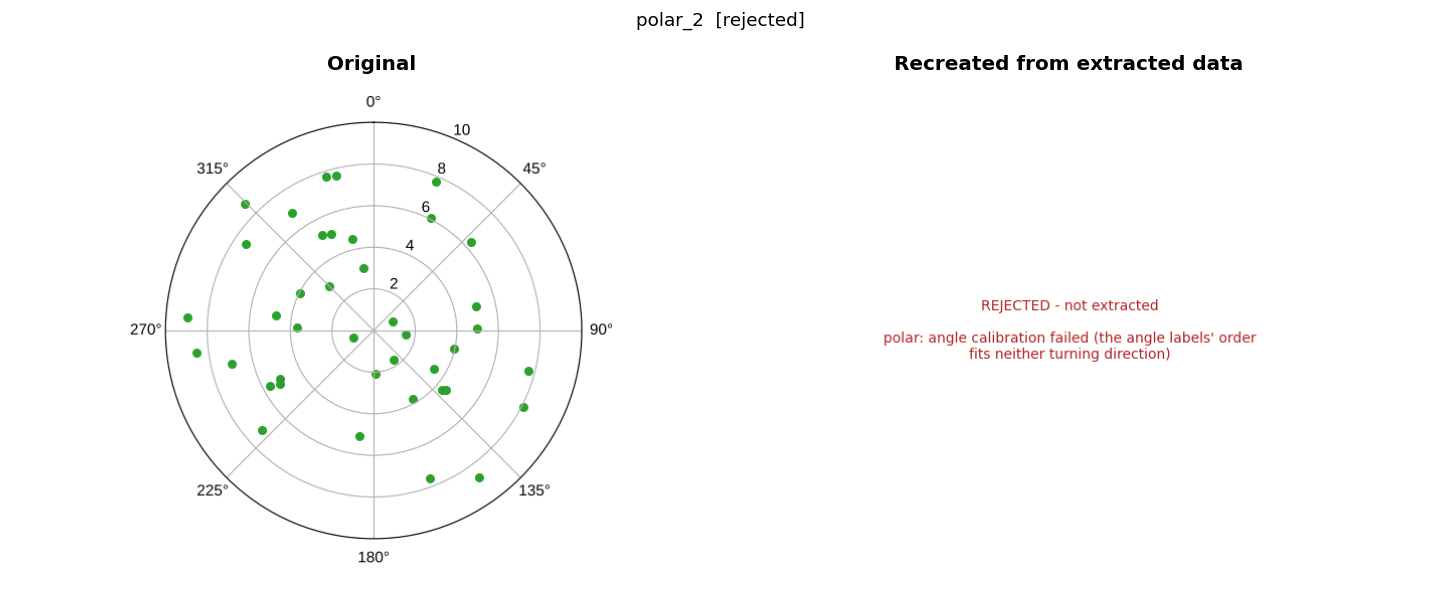

polar_3              REJECTED  type: polar  rows: 75
                      self-check failed: radial label fit (px) = 7.9 (needs <= 3)


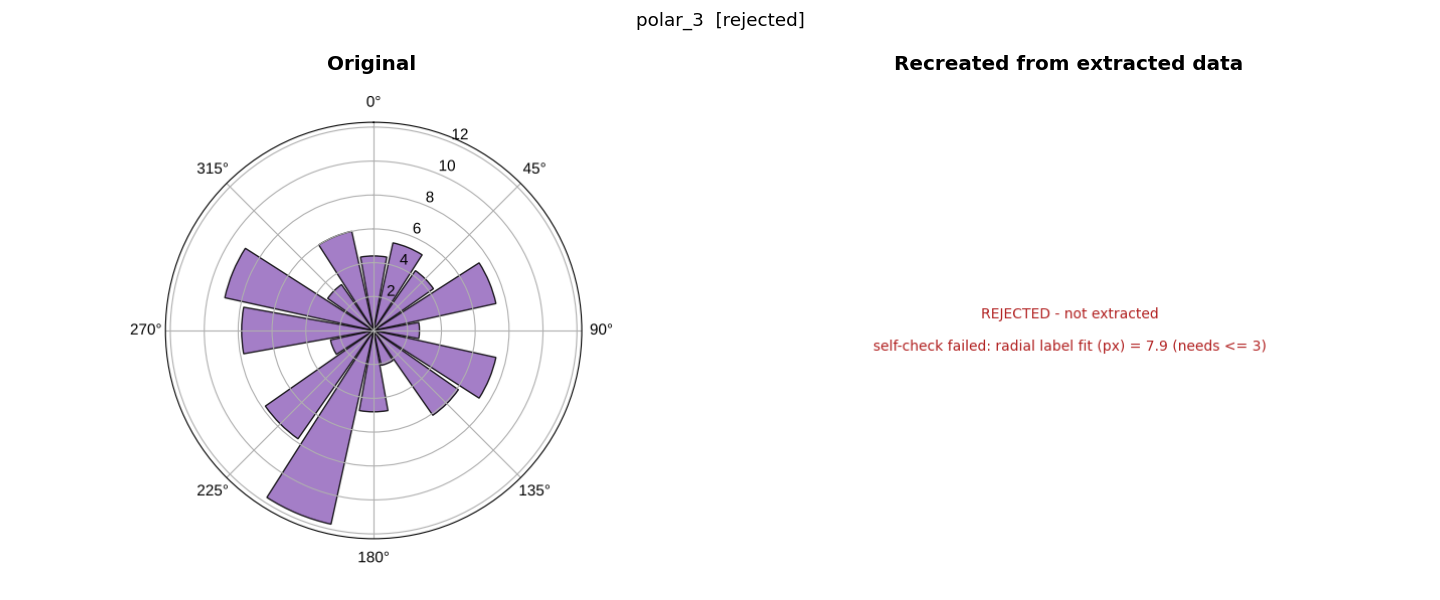

polar_4              OK        type: polar  rows: 12


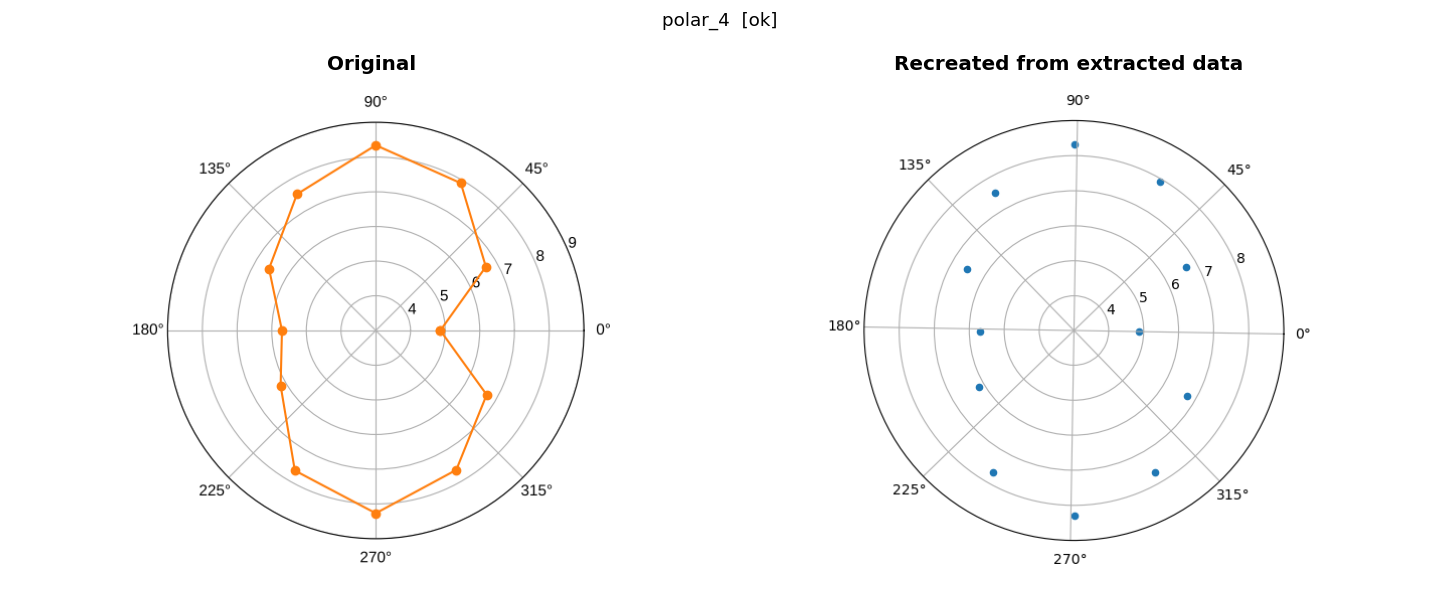

scatter3d_1          REJECTED  type: scatter3d  rows: 0
                      self-check failed: points extracted = 0 (needs >= 1)


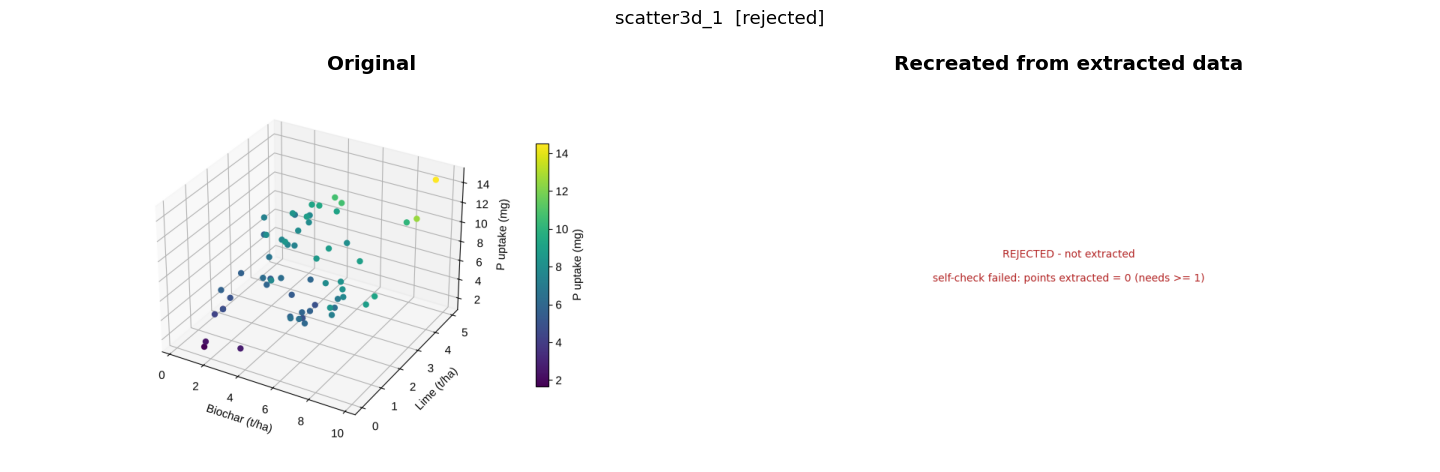

scatter3d_2          FLAGGED   type: scatter3d  rows: 57
                      depth not recoverable: no colour bar for z and no stems - x, y, z are guesses along each marker's line of sight; kept out of the accuracy scores


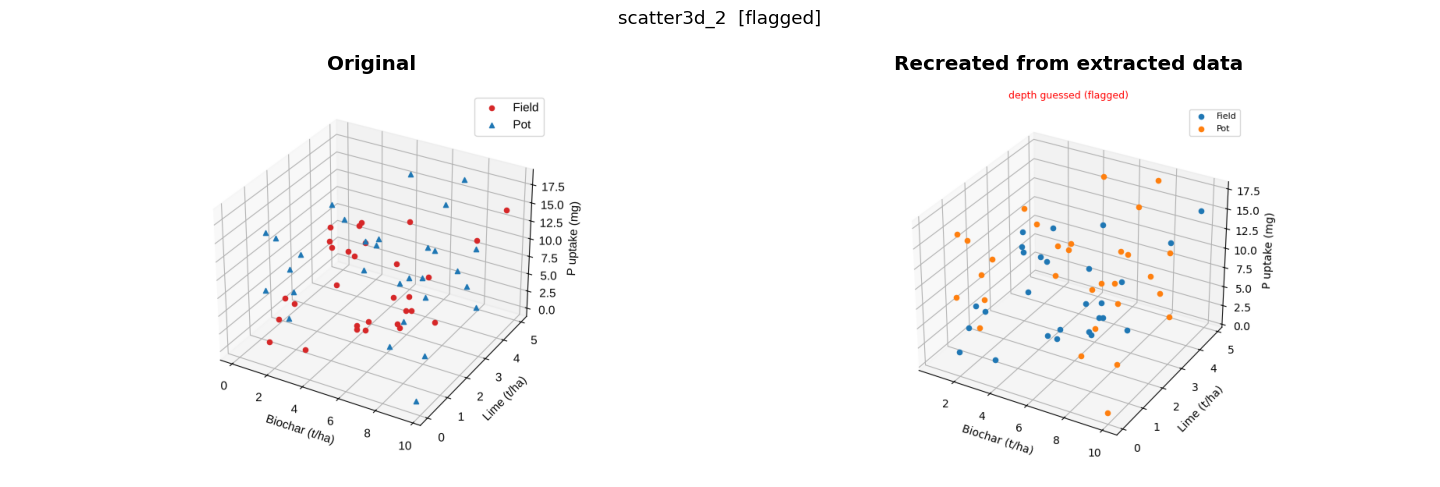

scatter3d_3          REJECTED  type: scatter3d  rows: 0
                      self-check failed: points extracted = 0 (needs >= 1)


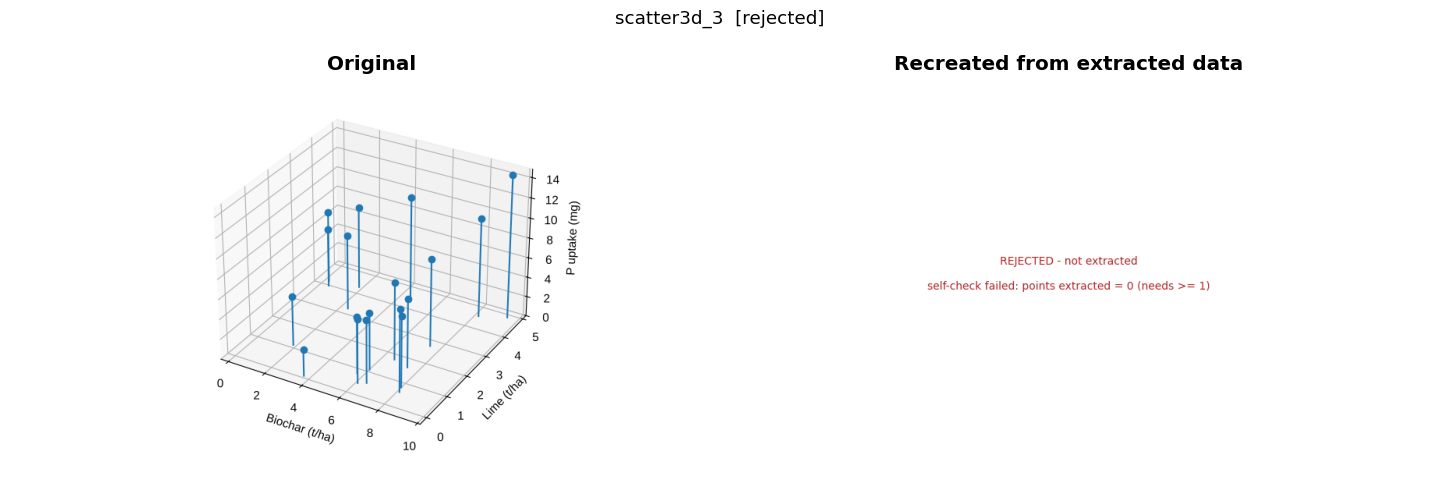

stacked_1            OK        type: stacked_bar  rows: 15


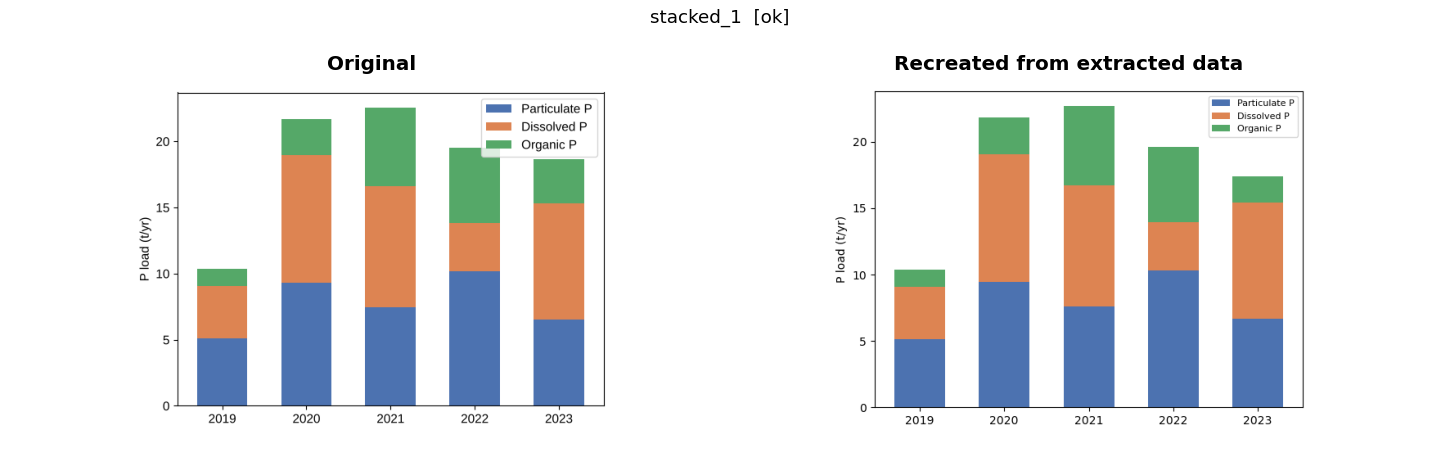

stacked_2            REJECTED  type: stacked_bar  rows: 0
                      bar chart: the value axis has no numeric calibration


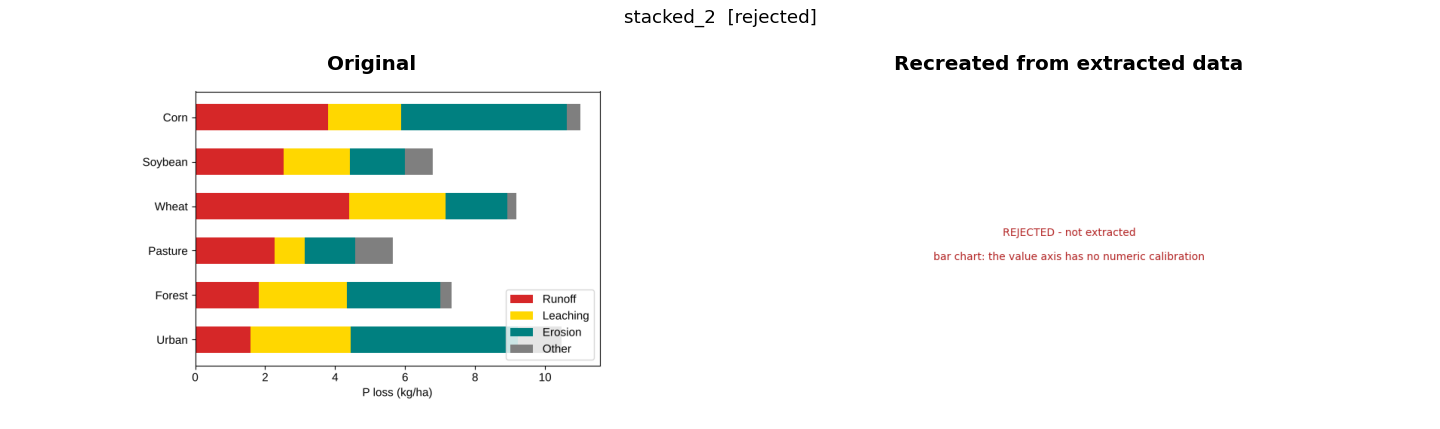

stacked_3            OK        type: stacked_bar  rows: 12


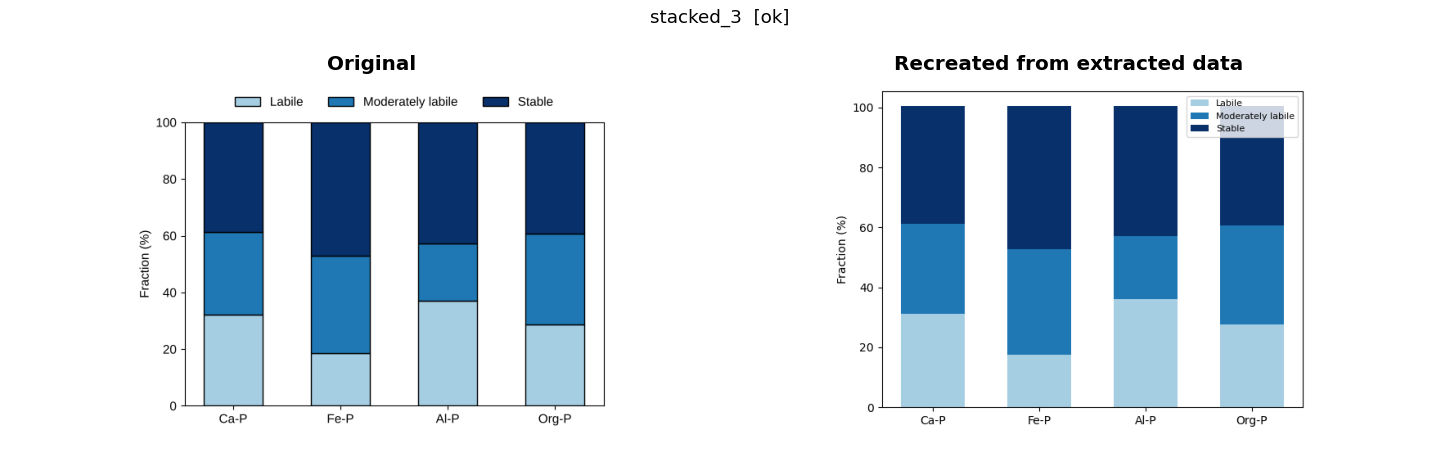

surface3d_1          OK        type: surface3d  rows: 2307


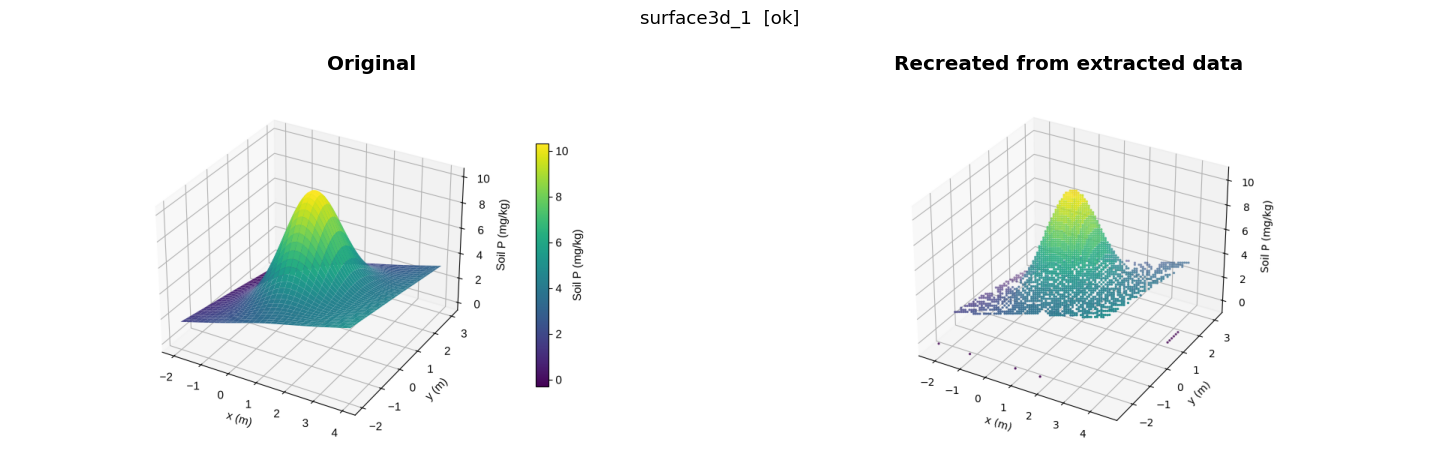

surface3d_2          OK        type: surface3d  rows: 5855


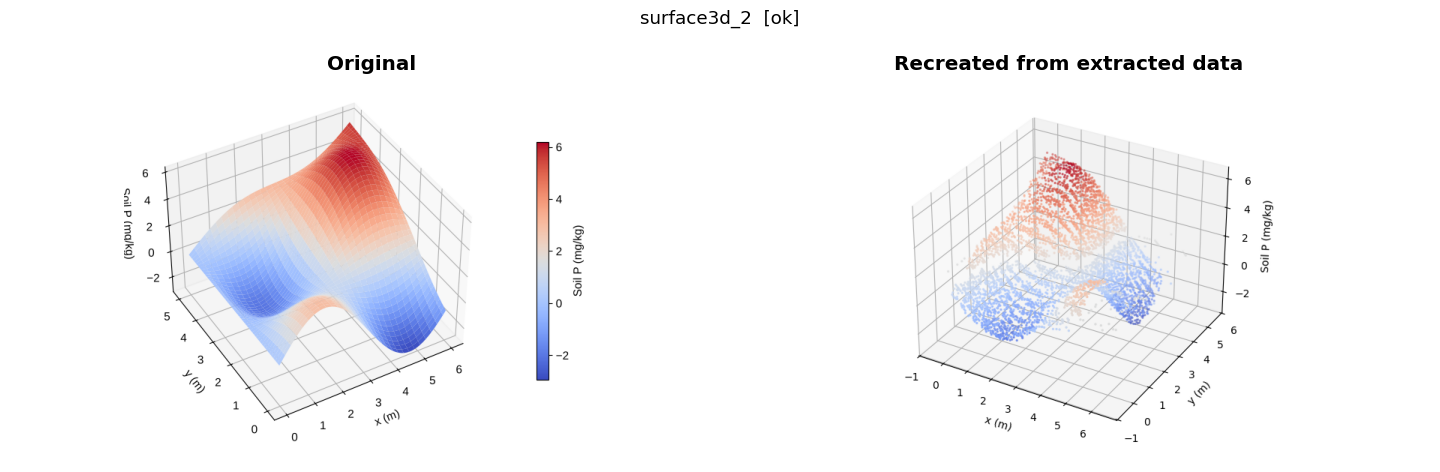

surface3d_3          FLAGGED   type: surface3d  rows: 750
                      depth not recoverable: no colour bar - the surface's z cannot be read from one view; points are guesses along each pixel's line of sight; kept out of the accuracy scores


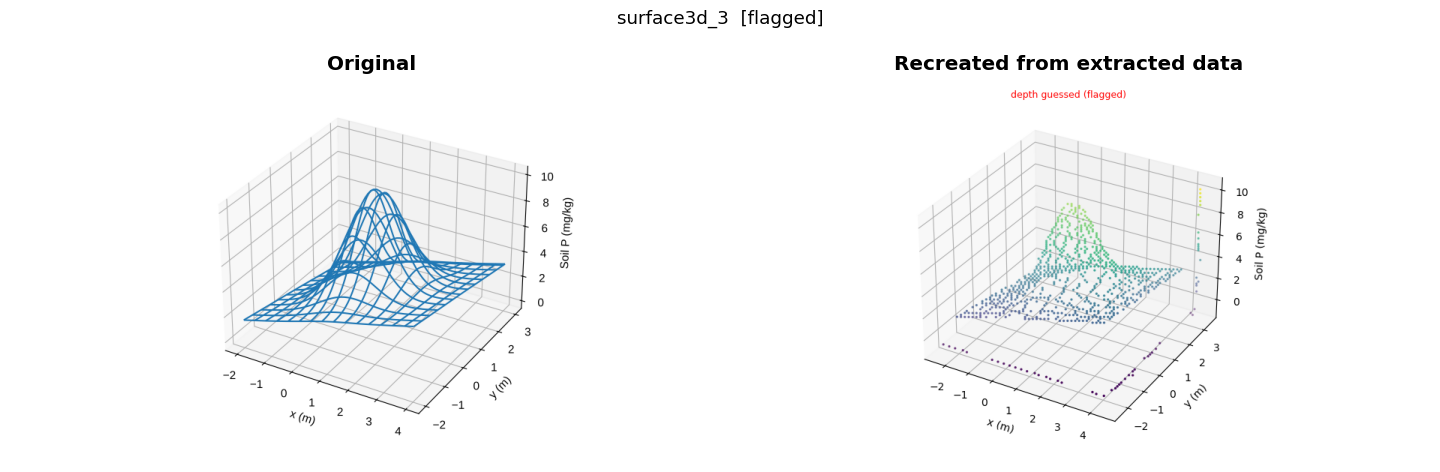

unknown_dendrogram   REJECTED  type: other  rows: 0
                      unsupported chart type (other)


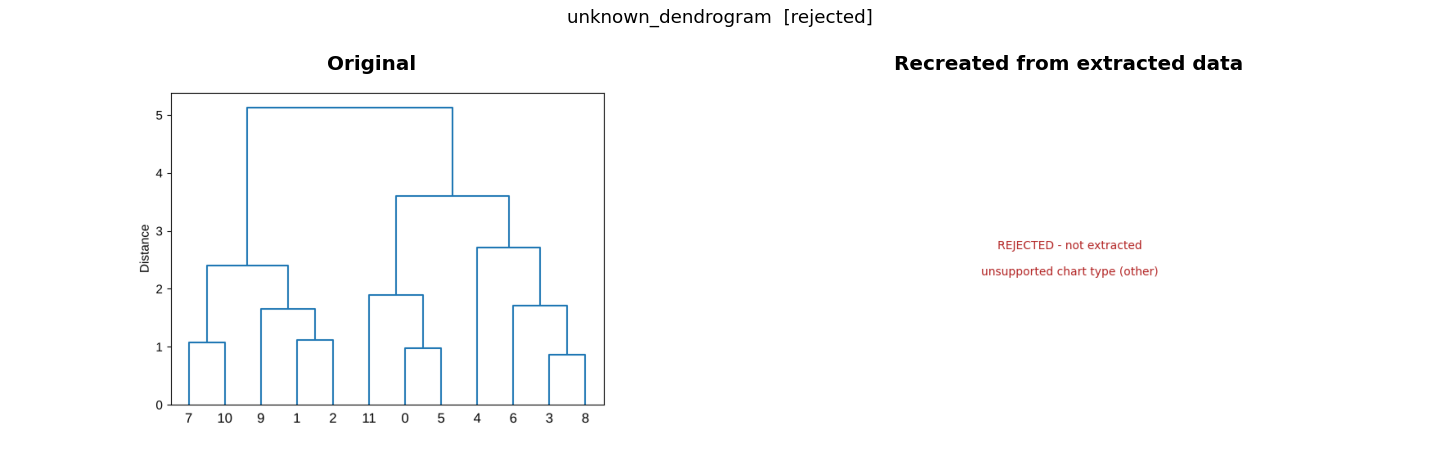

unknown_micrograph   REJECTED  type: other  rows: 0
                      unsupported chart type (other)


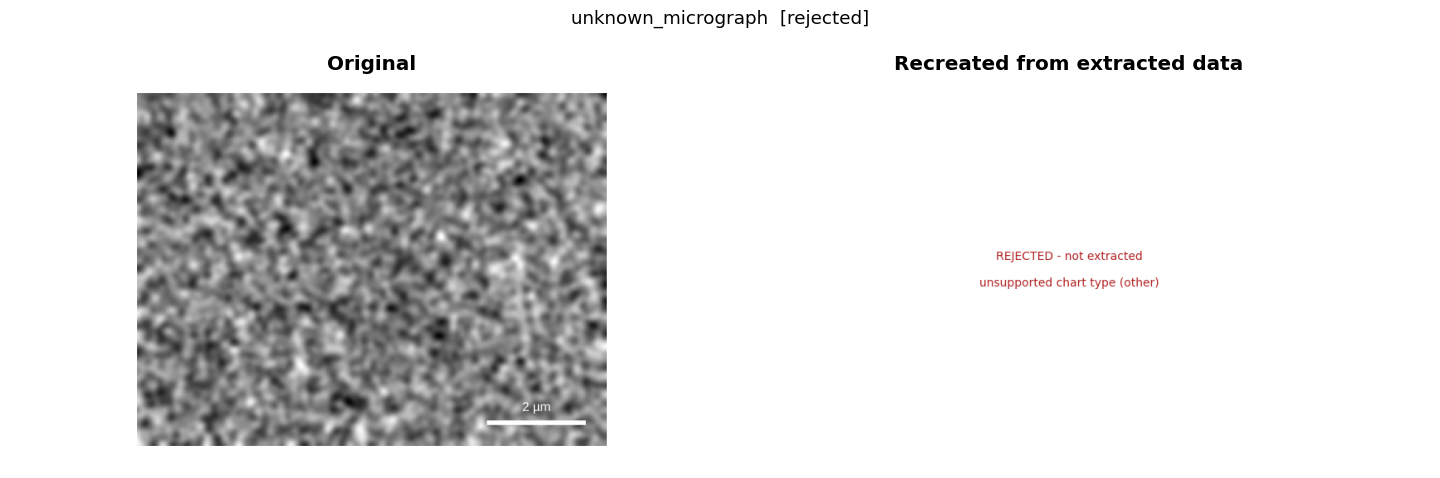

unknown_multipanel   REJECTED  type: None  rows: 70
                      4 plot panels (axes frames) in one image - split the figure into single plots first
                      no pixels found for series 'a'
                      no pixels found for series 'c'


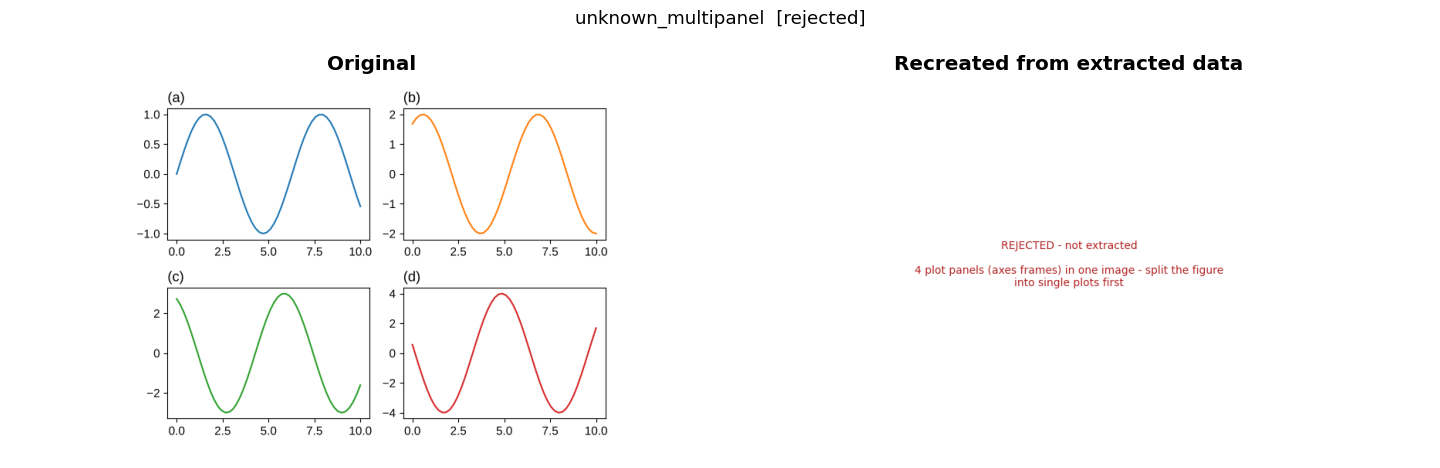

unknown_network      REJECTED  type: other  rows: 0
                      unsupported chart type (other)


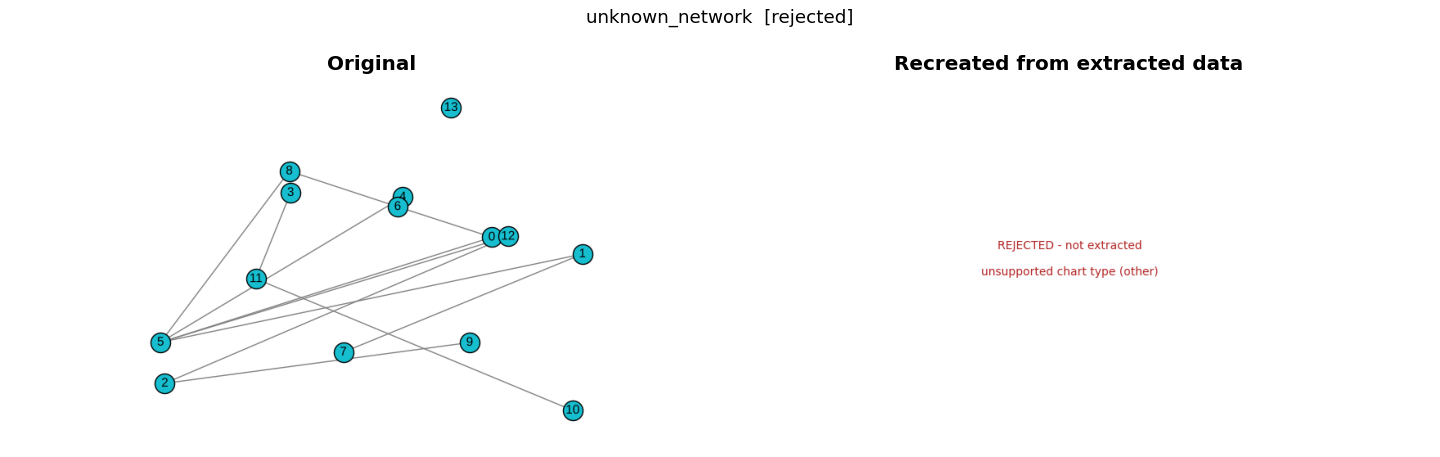

unknown_radar        REJECTED  type: polar  rows: 0
                      polar: angle calibration failed (6 angle labels found outside the circle, 0 read)


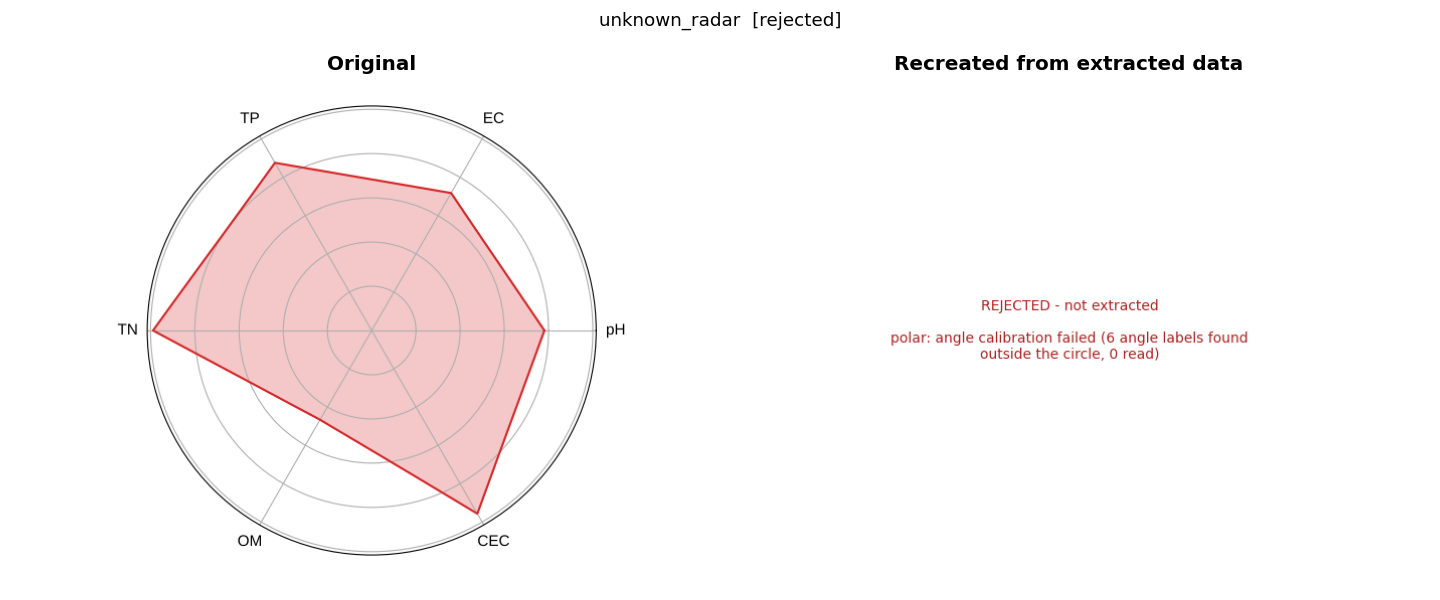

unknown_schematic    REJECTED  type: other  rows: 0
                      unsupported chart type (other)


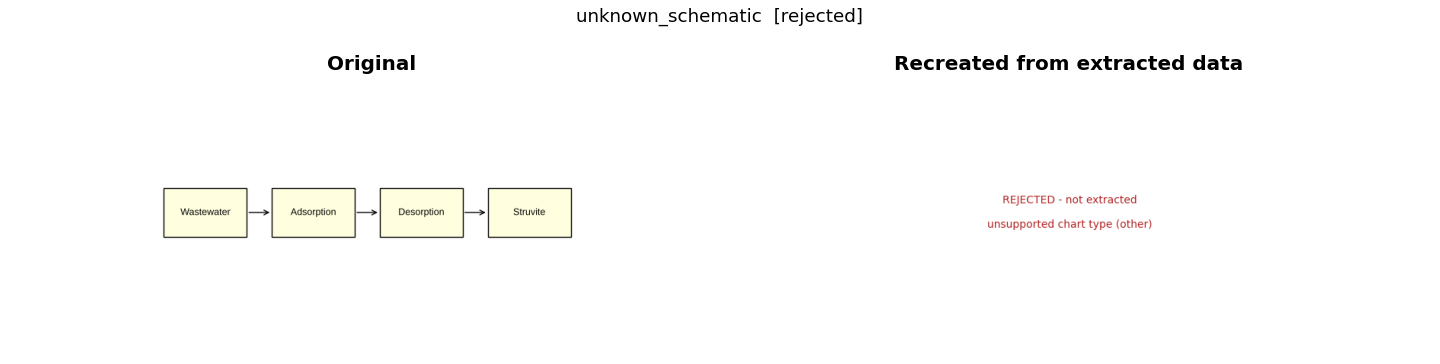

unknown_table        REJECTED  type: other  rows: 0
                      unsupported chart type (other)


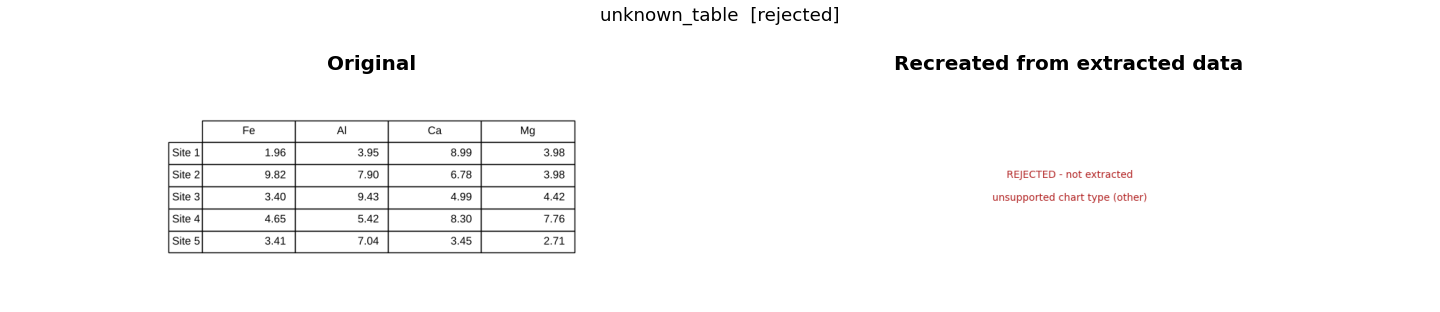

unknown_ternary      REJECTED  type: None  rows: 25
                      self-check failed: x-axis has numeric tick labels = no (needs yes)
                      no pixels found for series 'Silt'
                      no pixels found for series 'Clay'


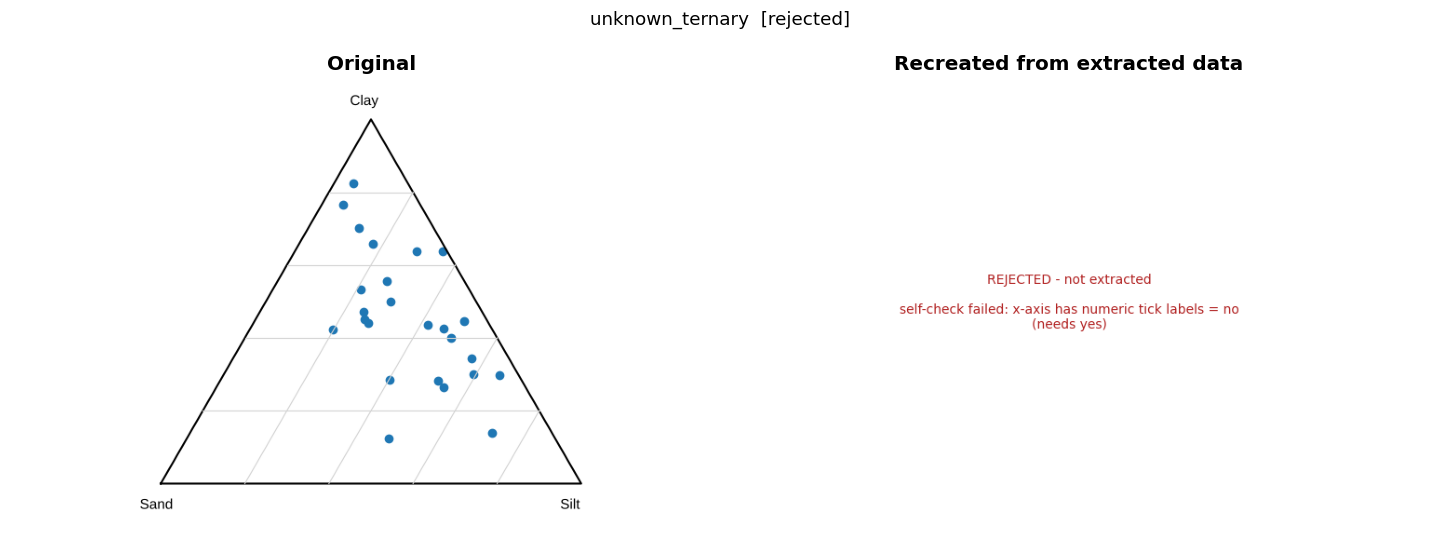

unknown_venn         REJECTED  type: other  rows: 0
                      unsupported chart type (other)


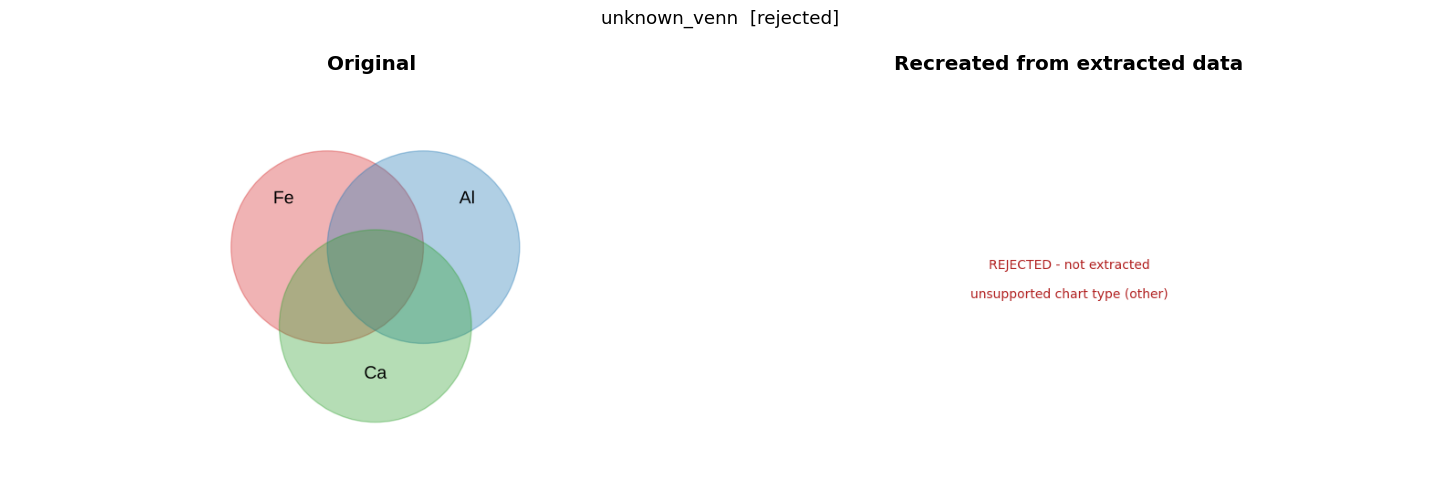

unknown_violin       REJECTED  type: other  rows: 0
                      unsupported chart type (other)


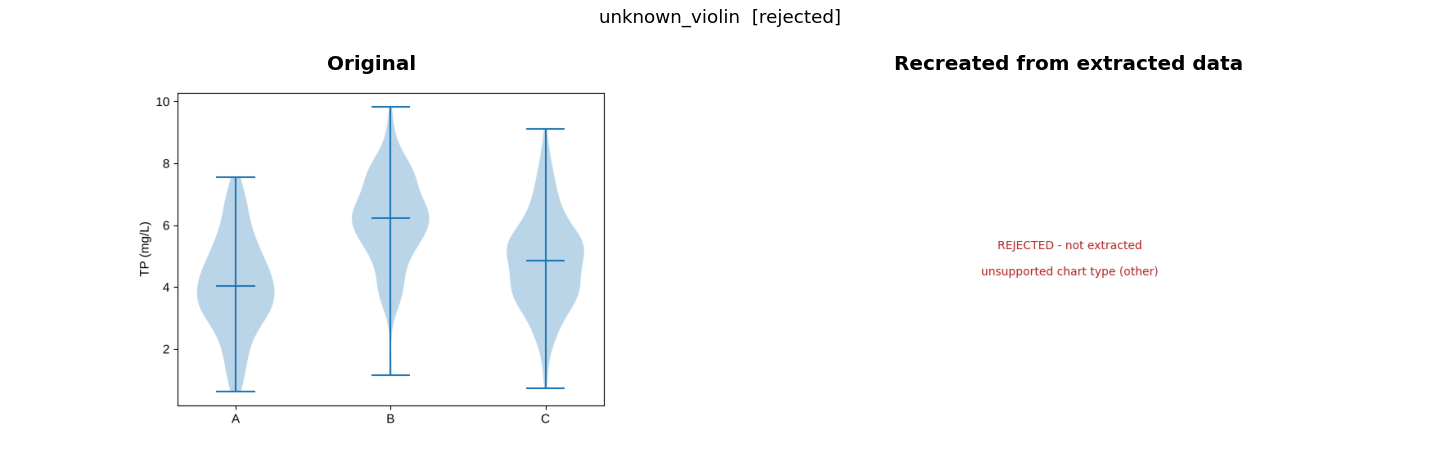

In [5]:
results, t_dig = {}, {}
for name, img in IMAGES.items():
    t = time.time()
    res = pipeline(img, specs[name])
    t_dig[name] = time.time() - t
    results[name] = res
    (OUT / name / "extraction.json").write_text(json.dumps(_jsonable(res), indent=1))
    csv_path = OUT / name / "extracted.csv"
    if csv_path.exists():
        csv_path.unlink()                      # a rejected image must not keep an old CSV
    E.write_csv(res, csv_path)
    rec = recreate(res, OUT / name / "recreated.png")
    side_by_side(img, rec, OUT / name / "side_by_side.png", f"{name}  [{res['status']}]")
    n_rows = len(res["table"]) if "table" in res else sum(len(d.get("x", [])) for d in res["series"].values())
    print(f"{name:20s} {res['status'].upper():9s} type: {res.get('chart_type')}  rows: {n_rows}")
    for r_ in res["status_reasons"]:
        print(f"{'':22s}{r_}")
    for w in res["warnings"]:
        print(f"{'':22s}{w}")
    display(IPImage(filename=str(OUT / name / "side_by_side.png"), width=950))

## 2b · Status of every image: ok / flagged / rejected, with the self-checks

In [6]:
status = pd.DataFrame([{"figure": n, "chart type (VLM)": specs[n].get("chart_type"), "status": r["status"],
                        "reason": "; ".join(r["status_reasons"])[:160],
                        "checks passed": f"{sum(1 for c in r['checks'] if c[3])}/{len(r['checks'])}"} for n, r in results.items()]).set_index("figure")
display(status.style.apply(lambda r: ["background-color: #fde2e2" if r["status"] == "rejected" else
                                      ("background-color: #fff3cd" if r["status"] == "flagged" else "") for _ in r], axis=1))
status.to_csv(OUT / "status.csv")
for n, r in results.items():
    if r["checks"]:
        print(n, " | ".join(f"{c[0]}: {c[1]} ({'ok' if c[3] else 'FAIL'})" for c in r["checks"]))

,chart type (VLM),status,reason,checks passed
figure,,,,
bar3d_1,bar3d,ok,,2/2
bar3d_2,bar3d,ok,,2/2
bar3d_3,bar3d,ok,,2/2
box_1,box,ok,,3/3
box_2,box,rejected,self-check failed: boxes found / expected = 5/25 (needs equal),2/3
box_3,box,rejected,box plot: the value axis has no numeric calibration,0/0
box_4,box,ok,,3/3
box_5,box,ok,,3/3
field_1,contour,ok,,3/3


bar3d_1 3-D camera reprojection of the ticks (px): 0.4 (ok) | bars read / grid cells: 16/20 (ok)
bar3d_2 3-D camera reprojection of the ticks (px): 0.38 (ok) | bars read / grid cells: 15/20 (ok)
bar3d_3 3-D camera reprojection of the ticks (px): 0.83 (ok) | bars read / grid cells: 11/20 (ok)
box_1 value-axis label fit (px): 0.27 (ok) | boxes found / expected: 5/5 (ok) | boxes without a median line: 0 (ok)
box_2 value-axis label fit (px): 0.27 (ok) | boxes found / expected: 5/25 (FAIL) | boxes without a median line: 0 (ok)
box_4 value-axis label fit (px): 0.0 (ok) | boxes found / expected: 6/6 (ok) | boxes without a median line: 0 (ok)
box_5 value-axis label fit (px): 0.24 (ok) | boxes found / expected: 4/4 (ok) | boxes without a median line: 0 (ok)
field_1 axis label fit (px): 0.57 (ok) | colorbar label fit (px): 0.23 (ok) | sample points whose colour is not on the scale (%): 0.0 (ok)
field_2 colorbar label fit (px): 0.22 (ok) | median cell colour distance to the colour scale: 1.0 (ok)

## 3 · Ground truth vs extracted, point by point
For each plot: the ground truth placed on the image with the benchmark's own calibration (black circles — they sit on the markers, so the ground truth is right), the extracted points (orange ×) and the missed points (red circles); then one row per ground-truth point.
*error* = |y extracted − y truth| / span of that series' y-axis (for a broken axis: the span of its own segment; for a bar: the axis its category uses; for a pie: 100 %); *point accuracy* = 100 − error; *hit* = error ≤ 5 %. Traced curves are compared at 25 evenly spaced x; bars and slices are matched by category.

In [8]:
if SCORED:
    point_tables, summary = {}, []
    for fid, img in IMAGES.items():
        if results[fid]["status"] != "ok":
            print(f"{fid}: {results[fid]['status']} - not scored ({'; '.join(results[fid]['status_reasons'])[:120]})")
            continue
        mapping = E.match_names([n for n, d in results[fid]["series"].items() if d["x"]], list(GT[fid]["series"]))
        df = RP.point_table(fid, GT[fid], results[fid], mapping)
        point_tables[fid] = df
        df.to_csv(OUT / fid / "points_truth_vs_extracted.csv", index=False)
        from autodig.prf import prf_rebuilt
        pr = prf_rebuilt(fid, GT[fid], results[fid], mapping, CONFIG["hit_threshold"])
        summary.append(RP.summary_row(fid, df) | {k: pr[k] for k in ("precision %", "recall %", "F1 %", "extracted items")})
        RP.gt_on_image(fid, img, GT[fid], results[fid], FIGURES, df, OUT / fid / "truth_on_image.png"); plt.show()
        fmt = lambda v: v if isinstance(v, str) else f"{v:.4g}"
        display(df.style.format({"x": fmt, "y truth": "{:.4g}", "y extracted": "{:.4g}"}, na_rep="-")
                  .apply(lambda r: ["background-color: #fde2e2" if r["hit (<= 5 %)"] != "yes" else "" for _ in r], axis=1)
                  .hide(axis="index").set_caption(fid))
elif MODE == "gallery":
    # Pick up scoring fixes when rerunning this cell in an existing kernel.
    import importlib
    importlib.reload(GE)
    gal_tables, gal_summary = {}, []
    for n in IMAGES:
        df = GE.score(GT[n], results[n], CONFIG["hit_threshold"])
        gal_tables[n] = df
        if len(df):
            df.to_csv(OUT / n / "points_truth_vs_extracted.csv", index=False)
        gal_summary.append(GE.summary(n, df, results[n]["status"], GT[n], results[n], CONFIG["hit_threshold"]) | {"truth type": GT[n].get("type")})
        if len(df) and results[n]["status"] != "rejected":
            worst = df.sort_values("error %", ascending=False).head(6)
            display(worst.style.format({"truth": "{:.4g}", "extracted": "{:.4g}"}, na_rep="-").hide(axis="index")
                    .set_caption(f"{n} [{results[n]['status']}] - 6 worst of {len(df)} items"))
else:
    print("no ground truth for these images")

item,truth,extracted,error %,hit
0.5 / pH 10,5.2,-,100.000000,False
1 / pH 8,5.9,-,100.000000,False
1 / pH 10,19.1,-,100.000000,False
2 / pH 10,11.4,-,100.000000,False
0.5 / pH 12,28.3,27.04,3.230000,True
1 / pH 12,35.3,34.43,2.240000,True


item,truth,extracted,error %,hit
2 / pH 8,25.3,-,100.000000,False
0.5 / pH 10,16,-,100.000000,False
1 / pH 10,5.5,-,100.000000,False
2 / pH 10,21.8,-,100.000000,False
2 / pH 6,27.8,-,100.000000,False
1 / pH 6,6.4,26.2,54.390000,False


item,truth,extracted,error %,hit
5 / pH 12,10.2,-,100.000000,False
2 / pH 6,7.6,-,100.000000,False
5 / pH 10,5.5,-,100.000000,False
5 / pH 8,12.1,-,100.000000,False
5 / pH 6,8.4,-,100.000000,False
2 / pH 10,16.4,-,100.000000,False


item,truth,extracted,error %,hit
P removal (%) / BC700 / flier,30.88,-,100.000000,False
P removal (%) / BC500 / whislo,14.36,14.19,0.350000,True
P removal (%) / BC300 / q1,12.97,12.83,0.310000,True
P removal (%) / BC700 / flier,30.57,30.7,0.290000,True
P removal (%) / Control / whishi,15.66,15.79,0.260000,True
P removal (%) / BC300 / whishi,22.61,22.73,0.260000,True


item,truth,extracted,error %,hit
Outflow / Summer / whishi,6.426,6.465,0.620000,True
Outflow / Summer / whislo,2.037,2,0.570000,True
Outflow / Autumn / whislo,1.615,1.581,0.520000,True
Outflow / Spring / whishi,4.504,4.535,0.470000,True
Outflow / Spring / whislo,0.6778,0.6512,0.410000,True
Inflow / Autumn / whishi,7.174,7.209,0.400000,True


item,truth,extracted,error %,hit
P removal (%) / BC700 / flier,30.88,-,100.000000,False
P removal (%) / BC700 / flier,30.57,30.74,0.550000,True
P removal (%) / BC500 / whishi,27.52,27.6,0.270000,True
P removal (%) / BC500 / q3,21.18,21.26,0.260000,True
P removal (%) / BC300 / whishi,22.61,22.69,0.250000,True
P removal (%) / Control / q3,13.41,13.48,0.220000,True


... (17 outputs left out)

item,truth,extracted,error %,hit
Moderately labile / Ca-P,28.95,30.05,1.100000,True
Moderately labile / Fe-P,34.15,35.25,1.090000,True
Labile / Ca-P,32.28,31.2,1.080000,True
Labile / Fe-P,18.66,17.62,1.030000,True
Labile / Org-P,28.75,27.73,1.010000,True
Moderately labile / Org-P,32,32.93,0.930000,True


item,truth,extracted,error %,hit
"(-2, -2)",1.6,-,100.000000,False
"(-0.6, 1.17)",2.253,-,100.000000,False
"(1, 1.33)",7.102,-,100.000000,False
"(1.2, 1.33)",7.089,-,100.000000,False
"(1.4, 1.33)",6.833,-,100.000000,False
"(1.6, 1.33)",6.388,-,100.000000,False


item,truth,extracted,error %,hit
"(0, 0)",0,-,100.000000,False
"(0, 1.67)",0,-,100.000000,False
"(3.4, 1.33)",0.7263,-,100.000000,False
"(3.8, 1.33)",0.5815,-,100.000000,False
"(4, 1.33)",0.5326,-,100.000000,False
"(4.2, 1.33)",0.5049,-,100.000000,False


item,truth,extracted,error %,hit
"(-2, -2)",1.6,1.59,100.000000,False
"(1.6, 1.5)",5.591,-,100.000000,False
"(-2, 1.5)",0.2102,-,100.000000,False
"(-1.8, 1.5)",0.3421,-,100.000000,False
"(-1.6, 1.5)",0.4853,-,100.000000,False
"(-1.4, 1.5)",0.6483,-,100.000000,False


## 4 · Overall per plot
**Precision / recall / F1** (`autodig/prf.py`) next to the hit rate. *Recall* = true items recovered within 5 % of the axis span; *precision* = extracted items that are within 5 % of a true item (invented points, split bars, an extra series count against it); *F1* = their harmonic mean. Markers are paired one-to-one (Hungarian; x must also agree within half the marker spacing), bars / slices / cells by category, traced curves / colour maps / surfaces sample-wise (each extracted sample against the true curve). Rejected and flagged plots are not in the means.

In [9]:
if SCORED:
    acc = pd.DataFrame(summary).set_index("figure")
    acc["VLM s"] = [spec_info[f].get("seconds") for f in acc.index]
    acc["digitize s"] = [round(t_dig[f], 2) for f in acc.index]
    acc.loc["MEAN"] = acc.mean(numeric_only=True).round(1)
    acc.loc["MEAN", "truth points"] = acc["truth points"][:-1].sum()
    acc.loc["MEAN", "missed points"] = acc["missed points"][:-1].sum()
    acc.loc["MEAN", "extracted items"] = acc["extracted items"][:-1].sum()
    print(f"mean precision {acc.loc['MEAN', 'precision %']} %   recall {acc.loc['MEAN', 'recall %']} %   F1 {acc.loc['MEAN', 'F1 %']} %")
    display(acc)
    acc.to_csv(OUT / "accuracy.csv")
    who = getattr(reader, "model_id", "hand-written spec (dry run)").split("/")[-1]
    mine = {"model": "vlm+digitizer", "label": f"{who} reads text + pixel digitizer (notebook 03)",
            "hit_rate_rebuilt": acc.loc["MEAN", "hit rate %"], "accuracy_rebuilt": acc.loc["MEAN", "accuracy %"],
            "coverage_rebuilt": acc.loc["MEAN", "coverage %"],
            "precision_rebuilt": acc.loc["MEAN", "precision %"], "recall_rebuilt": acc.loc["MEAN", "recall %"],
            "f1_rebuilt": acc.loc["MEAN", "F1 %"],
            "sec_per_image_rebuilt": (acc.loc["MEAN", "VLM s"] or 0) + acc.loc["MEAN", "digitize s"], "figures_rebuilt": len(IMAGES)}
    lb = RP.leaderboard_with(BENCH, mine)
    lb.to_csv(OUT / "leaderboard.csv", index=False)
    RP.leaderboard_chart(lb, OUT / "leaderboard.png", rebuilt_only=True); plt.show()
    print("saved:", OUT / "accuracy.csv", ",", OUT / "leaderboard.csv", "and <figure>/points_truth_vs_extracted.csv")

In [10]:
if MODE == "gallery":
    gs = pd.DataFrame(gal_summary).set_index("figure")
    display(gs)
    gs.to_csv(OUT / "gallery_accuracy.csv")
    ok = gs[(gs["status"] == "ok") & (gs["truth items"] > 0)]
    supported = gs[gs["truth type"] != "unsupported"]
    unknown = gs[gs["truth type"] == "unsupported"]
    print(f"supported plots: {len(supported)}  ok: {(supported.status == 'ok').sum()}  flagged: {(supported.status == 'flagged').sum()}  "
          f"rejected: {(supported.status == 'rejected').sum()}")
    print(f"mean over the {len(ok)} ok plots:  hit rate {ok['hit rate %'].mean():.1f} %   accuracy {ok['accuracy %'].mean():.1f} %   coverage {ok['coverage %'].mean():.1f} %")
    print(f"                           precision {ok['precision %'].mean():.1f} %   recall {ok['recall %'].mean():.1f} %   F1 {ok['F1 %'].mean():.1f} %")
    print(f"unsupported plots correctly rejected: {(unknown.status == 'rejected').sum()} / {len(unknown)}")
    print("per chart type (ok plots):")
    display(ok.groupby("truth type")[["precision %", "recall %", "F1 %", "hit rate %", "accuracy %", "coverage %"]].mean().round(1))

,status,truth items,hit rate %,accuracy %,coverage %,mean error % (found),precision %,recall %,F1 %,extracted items,truth type
figure,,,,,,,,,,,
bar3d_1,ok,20,80.0,79.1,80.0,1.08,100.0,80.0,88.9,16.0,bar3d
bar3d_2,ok,20,65.0,69.9,75.0,6.81,86.7,65.0,74.3,15.0,bar3d
bar3d_3,ok,20,30.0,52.8,55.0,3.91,54.5,30.0,38.7,11.0,bar3d
box_1,ok,32,96.9,96.7,96.9,0.16,100.0,96.9,98.4,31.0,box
box_2,rejected,32,96.9,96.7,96.9,0.13,0.0,96.9,0.0,0.0,box
box_3,rejected,26,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,box
box_4,ok,31,100.0,99.8,100.0,0.21,100.0,100.0,100.0,31.0,box
box_5,ok,25,96.0,95.9,96.0,0.15,100.0,96.0,98.0,24.0,box
field_1,ok,1681,97.6,99.4,100.0,0.58,98.6,97.6,98.1,3600.0,field


supported plots: 34  ok: 25  flagged: 2  rejected: 7
mean over the 25 ok plots:  hit rate 72.6 %   accuracy 78.5 %   coverage 82.8 %
                           precision 76.8 %   recall 72.6 %   F1 74.4 %
unsupported plots correctly rejected: 10 / 10
per chart type (ok plots):


,precision %,recall %,F1 %,hit rate %,accuracy %,coverage %
truth type,,,,,,
bar3d,80.4,58.3,67.3,58.3,67.3,70.0
box,100.0,97.6,98.8,97.6,97.5,97.6
field,74.2,72.6,73.4,72.6,74.5,75.0
heatmap,75.6,75.6,75.6,75.6,86.8,100.0
histogram,75.0,75.0,75.0,75.0,74.8,75.0
polar,100.0,100.0,100.0,100.0,99.0,100.0
stacked,64.4,64.4,64.4,64.4,72.7,75.0
surface3d,43.0,30.7,35.8,30.7,54.1,71.0


In [ ]:
# free the GPU / MPS memory (Qwen) / API usage (OpenAI)
if hasattr(reader, "usage"):
    print("OpenAI calls:", reader.usage["calls"], " input tokens:", reader.usage["input_tokens"], " output tokens:", reader.usage["output_tokens"])
if hasattr(reader, "unload"):
    reader.unload()